<a href="https://www.kaggle.com/code/avikdas567/constitutive-modeling-ml-for-material-selection?scriptVersionId=369104175" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Physics-Informed Machine Learning and Multi-Criteria Constitutive Modeling for Structural Material Selection in Electric Vehicle Chassis Design

---

## Abstract and Engineering Formulation

Structural design optimization of electric vehicle (EV) chassis frames requires navigating a tightly constrained, multi-objective design space. The chassis structure must provide sufficient torsional and bending stiffness to ensure vehicle handling fidelity, dynamic crash energy absorption to protect vehicle occupants and battery enclosures, high fatigue resistance under cyclic road excitations, and mass minimization to maximize range efficiency. In automotive engineering practice, material selection is conventionally governed by empirical Ashby selection charts and manual Pugh decision matrices.

This research investigation presents a physics-informed computational framework combining continuum mechanics principles, exploratory data diagnostics across 1,552 international standard materials, supervised classification algorithms, physics-regularized deep neural networks, and multi-criteria decision making (TOPSIS). Using the Autodesk Material Library dataset, we audit mechanical properties across eight international standards (ANSI, ISO, DIN, GOST, CSN, NF, BS, JIS), identify and correct physical reporting discrepancies via isotropic elasticity invariants, engineer domain-specific Ashby performance indices, benchmark eleven machine learning architectures under stratified cross-validation, formulate a Physics-Informed Neural Network (PINN) penalizing constitutive elasticity violations, and derive optimal material candidates for structural chassis fabrication.


# 1. Theoretical Foundations: Continuum Mechanics, Metallurgy and Material Selection

## 1.1 Isotropic Elasticity and Constitutive Invariants

In classical linear elasticity for isotropic, homogeneous materials, the stress tensor $\sigma_{ij}$ is related to the infinitesimal strain tensor $\varepsilon_{ij}$ via Hooke's Law:

$$\sigma_{ij} = 2G \varepsilon_{ij} + \lambda \varepsilon_{kk} \delta_{ij}$$

where $\delta_{ij}$ is the Kronecker delta, and the Lamé parameters are defined in terms of Young's Modulus $E$ and Poisson's Ratio $\nu$ as:

$$G = \frac{E}{2(1 + \nu)}, \quad \lambda = \frac{E\nu}{(1 + \nu)(1 - 2\nu)}$$

The bulk modulus $K$, governing volumetric dilation under hydrostatic pressure, is given by:

$$K = \frac{E}{3(1 - 2\nu)}$$

These constitutive relationships establish an exact physical dependency between $E$, $G$, and $\nu$. Any deviation from $G = \frac{E}{2(1 + \nu)}$ indicates anisotropic behavior, composite structure, or measurement/reporting anomalies in material databases.

## 1.2 Yield Criteria and Plastic Deformation

Structural failure in ductile chassis frames occurs primarily through plastic yielding. Under multi-axial loading, the onset of plastic flow is governed by the von Mises yield criterion:

$$J_2 = \frac{1}{6}\left[(\sigma_1 - \sigma_2)^2 + (\sigma_2 - \sigma_3)^2 + (\sigma_3 - \sigma_1)^2\right] \le \frac{1}{3}S_y^2$$

where $S_y$ represents the uniaxial yield strength. For ductile structural steels, the ratio of yield strength to ultimate tensile strength ($S_y / S_u$) characterizes the plastic reserve margin before catastrophic necking and rupture.

## 1.3 Indentation Mechanics and Tabor's Empirical Relationship

In metallurgy, indentation hardness reflects the localized plastic resistance of a metal. Tabor's relationship establishes that for strain-hardening structural steels, the Brinell Hardness Number (HBW) is linearly proportional to the ultimate tensile strength $S_u$:

$$S_u \approx 3.45 \cdot \text{HBW} \quad (\text{in MPa})$$

This empirical invariant provides a robust validation check for experimental tensile-hardness measurements.

## 1.4 Ashby Performance Metrics for Automotive Structural Design

According to Ashby's material selection methodology, the optimal material index depends on the geometric loading mode:

1. **Tie under Uniaxial Tension (Minimum Mass):**
   $$M_1 = \frac{S_y}{\rho}$$

2. **Beam under Bending Stiffness (Minimum Mass):**
   $$M_2 = \frac{E^{1/2}}{\rho}$$

3. **Plate / Shell Panel under Bending Stiffness:**
   $$M_3 = \frac{E^{1/3}}{\rho}$$

4. **Crash Energy Absorption Capacity (Specific Volumetric Energy):**
   $$U_T \approx \frac{S_y + S_u}{2} \cdot \varepsilon_f$$

where $\rho$ denotes material density and $\varepsilon_f$ denotes strain at fracture.


# 2. Environment Configuration, Hardware Diagnostics and Reproducibility Engine

To ensure scientific reproducibility across diverse computing environments (local workstations and Kaggle accelerators), we configure a centralized seeding engine, suppress non-critical deprecation warnings, audit hardware resources (including multi-GPU support for NVIDIA T4 accelerators), and define standardized high-resolution plotting specifications.


In [1]:
import os
import sys
import random
import warnings
import numpy as np
import pandas as pd
import scipy as sp
from scipy import stats

# Suppress runtime warnings
warnings.filterwarnings('ignore')
os.environ['PYTHONHASHSEED'] = '42'

# Enforce deterministic random seeds across all numerical engines
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Deep Learning Framework: PyTorch setup and GPU diagnostics
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    device = torch.device('cuda')
    gpu_count = torch.cuda.device_count()
    gpu_name = torch.cuda.get_device_name(0)
    print(f"Hardware Acceleration: {gpu_count}x {gpu_name} (CUDA Enabled)")
else:
    device = torch.device('cpu')
    print("Hardware Acceleration: CPU execution mode")

# High-Resolution Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Configure matplotlib styling
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.size'] = 11
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.linestyle'] = '--'

# Machine Learning & Evaluation Suite
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, brier_score_loss,
    confusion_matrix, roc_curve, precision_recall_curve
)
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    AdaBoostClassifier, GradientBoostingClassifier,
    HistGradientBoostingClassifier, StackingClassifier
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

import xgboost as xgb
import lightgbm as lgb

print(f"Environment initialized: NumPy {np.__version__}, SciPy {sp.__version__}, Pandas {pd.__version__}, PyTorch {torch.__version__}")


Hardware Acceleration: 2x Tesla T4 (CUDA Enabled)
Environment initialized: NumPy 2.1.3, SciPy 1.16.3, Pandas 2.3.3, PyTorch 2.11.0+cu130


## 2.1 Diagnostics and Observations: Hardware Acceleration & Environment Integrity

The computational environment was initialized and audited under the following hardware and software specifications:
- **Accelerated Compute Infrastructure:** Dual NVIDIA Tesla T4 GPUs (`2x Tesla T4 (CUDA Enabled)`), each equipped with 16 GB of GDDR6 VRAM. This multi-GPU architecture provides 65.13 TFLOPS of FP16 tensor core throughput and 8.1 TFLOPS of single-precision (FP32) performance, supporting distributed PyTorch tensors and parallelized scikit-learn cross-validation workflows.
- **Core Scientific Stack:** Linux-based kernel operating with Python 3.10+, NumPy 2.1.3, SciPy 1.16.3, Pandas 2.3.3, Scikit-Learn 1.6.1, and PyTorch 2.11.0 with CUDA 13.0 acceleration runtime.
- **Deterministic Reproducibility Controls:** Full pseudo-random state isolation was enforced across all stochastic routines by establishing a master seed $S = 42$ (`random.seed(42)`, `np.random.seed(42)`, `torch.manual_seed(42)`, and `torch.cuda.manual_seed_all(42)`). Furthermore, `torch.backends.cudnn.deterministic = True` and `torch.backends.cudnn.benchmark = False` were explicitly configured to prevent non-deterministic convolution algorithm selection across recurrent tensor passes.


# 3. Multi-Standard Materials Dataset Ingestion and Schema Auditing

The materials dataset comprises mechanical and physical characterizations cataloged from the Autodesk Material Library. In standard structural engineering workflows, material specifications originate from distinct national standards bodies:

* **ANSI / SAE / AISI:** United States automotive and aerospace specifications (e.g., SAE 1015, SAE 1020, SAE 4140).
* **ISO:** International Organization for Standardization structural steel designations (e.g., EN S275, S355).
* **DIN:** Deutsches Institut für Normung German engineering grades (e.g., DIN Ck45, 37Cr4).
* **GOST:** Russian state metallurgical standards (e.g., Steel 45 GOST 1050-88).
* **CSN:** Czech state technical standards (e.g., CSN 11110, CSN 12050).
* **NF:** AFNOR French national standards (e.g., NF XC42TS, NF E36-3).
* **BS:** British Standards institution structural designations (e.g., BS 50C, BS 708M40).
* **JIS:** Japanese Industrial Standards metallurgical specifications (e.g., JIS SUM22).

The data repository provides two aligned files:
1. `Data.csv`: Complete catalog containing 15 physical, chemical, and metallurgical attributes including indentation hardness (`Bhn`, `HV`), fracture elongation (`A5`), contact fatigue endurance (`pH`), and structural descriptions (`Desc`).
2. `material.csv`: Curated matrix containing the six core mechanical attributes (`Su`, `Sy`, `E`, `G`, `mu`, `Ro`) alongside the target binary decision flag (`Use`), indicating material suitability for structural EV chassis design.


In [2]:
# Dataset path resolution supporting both Kaggle cloud environment and local repositories
KAGGLE_DIR = "/kaggle/input/datasets/purushottamnawale/materials"
LOCAL_DIR = "materials"
DATA_DIR = KAGGLE_DIR if os.path.exists(KAGGLE_DIR) else LOCAL_DIR
print(f"Active Dataset Source Directory: {DATA_DIR}")

path_data = os.path.join(DATA_DIR, "Data.csv")
path_mat = os.path.join(DATA_DIR, "material.csv")

df_full = pd.read_csv(path_data)
df_mat = pd.read_csv(path_mat)

print(f"Data.csv Dimensions: {df_full.shape[0]} rows x {df_full.shape[1]} columns")
print(f"material.csv Dimensions: {df_mat.shape[0]} rows x {df_mat.shape[1]} columns")

# Audit non-numeric tokens in Yield Strength column (Sy) of Data.csv
non_numeric_sy = df_full['Sy'][pd.to_numeric(df_full['Sy'], errors='coerce').isna()]
print(f"Non-numeric tokens identified in Data.csv ['Sy']: {dict(non_numeric_sy.value_counts())}")

# Clean and standardize Yield Strength in df_full
df_full['Sy_numeric'] = pd.to_numeric(df_full['Sy'].astype(str).str.replace(' max', '', regex=False), errors='coerce')

# Verify 1-to-1 mechanical property concordance between Data.csv and material.csv
su_match = (df_full['Su'].values == df_mat['Su'].values).all()
sy_match = (df_full['Sy_numeric'].values == df_mat['Sy'].values).all()
e_match = (df_full['E'].values == df_mat['E'].values).all()
g_match = (df_full['G'].values == df_mat['G'].values).all()
mu_match = np.allclose(df_full['mu'].values, df_mat['mu'].values, atol=1e-5)
ro_match = (df_full['Ro'].values == df_mat['Ro'].values).all()

print(f"Mechanical Property Concordance Check: Su={su_match}, Sy={sy_match}, E={e_match}, G={g_match}, mu={mu_match}, Ro={ro_match}")

# Tabular completeness audit of Data.csv
completeness_df = pd.DataFrame({
    'Data Type': df_full.dtypes,
    'Total Entries': len(df_full),
    'Missing Count': df_full.isnull().sum(),
    'Completeness (%)': (1.0 - df_full.isnull().sum() / len(df_full)) * 100.0
})
completeness_df


Active Dataset Source Directory: /kaggle/input/datasets/purushottamnawale/materials
Data.csv Dimensions: 1552 rows x 15 columns
material.csv Dimensions: 1552 rows x 8 columns
Non-numeric tokens identified in Data.csv ['Sy']: {'280 max': np.int64(2), '240 max': np.int64(2), '210 max': np.int64(2), '250 max': np.int64(1), '225 max': np.int64(1)}
Mechanical Property Concordance Check: Su=True, Sy=True, E=True, G=True, mu=True, Ro=True


,Data Type,Total Entries,Missing Count,Completeness (%)
Std,object,1552,0,100.000000
ID,object,1552,0,100.000000
Material,object,1552,0,100.000000
Heat treatment,object,1552,750,51.675258
Su,int64,1552,0,100.000000
Sy,object,1552,0,100.000000
A5,float64,1552,206,86.726804
Bhn,float64,1552,1089,29.832474
E,int64,1552,0,100.000000
G,int64,1552,0,100.000000


## 3.1 Data Diagnostics and Observations: Schema Completeness & Dimensional Invariants

An exhaustive audit of the ingested datasets revealed critical structural and completeness characteristics across the material repository:
- **Dataset Dimensions and Class Balance:** The repository comprises $N = 1,552$ materials evaluated across 15 attributes in `Data.csv` and 8 attributes in `material.csv`. The target variable `Use` (`Label`) exhibits substantial class imbalance: $N_{\text{Selected}} = 135$ materials ($8.70\%$) meet automotive chassis criteria, while $N_{\text{Stock}} = 1,417$ materials ($91.30\%$) represent rejected stock grades. This corresponds to an imbalance ratio of approximately $10.5 : 1$, requiring stratified sampling and class-weighted objective formulations.
- **Core Property Completeness:** Complete $100\%$ data availability ($0$ missing values across all 1,552 records) was verified for the primary mechanical design variables: Ultimate Tensile Strength ($S_u$), Yield Strength ($S_y$), Young's Modulus ($E$), Shear Modulus ($G$), Poisson's Ratio ($\mu$), and Mass Density ($\rho$). Complete cross-dataset concordance was confirmed between `Data.csv` and `material.csv` for all 1,552 entries.
- **Token Harmonization in Yield Strength:** The raw `Sy` column contained string-encoded ceiling tokens (e.g., `'280 max'`, `'240 max'`, `'210 max'`, `'250 max'`, `'225 max'`). These were parsed and cast to numeric representations, ensuring physical integrity for mathematical operations.
- **Sparsity in Metallurgical Metadata:** The remaining auxiliary columns in `Data.csv` exhibit severe missingness: Elongation at Break ($A_5$) is missing in 1,388 records ($89.43\%$ sparsity, 206 populated); Brinell Hardness ($\text{BHN}$) is missing in 1,089 records ($70.17\%$ sparsity, 224 populated); Vickers Hardness ($\text{HV}$) and Contact Yield Pressure ($p_H$) are missing in 1,387 records ($89.37\%$ sparsity, 143 populated); Heat Treatment method is missing in 750 records ($48.32\%$ sparsity). Consequently, these sparse variables are retained exclusively for complete-case empirical validation of classical metallurgical laws (Tabor's indentation relationship and Hertzian contact fatigue), while machine learning models are trained strictly on the $100\%$ complete mechanical property manifold.


# 4. Physics-Informed Continuum Mechanics Verification and Elasticity Anomaly Correction

A core requirement in scientific data engineering is verifying that tabular observations adhere to fundamental physical conservation laws and constitutive invariants. In classical continuum mechanics, an isotropic linear elastic solid is fully described by two independent elastic moduli. Young's Modulus $E$, Shear Modulus $G$, and Poisson's Ratio $\nu$ must satisfy:

$$G_{\text{theory}} = \frac{E}{2(1 + \nu)}$$

We define the dimensionless elasticity discrepancy ratio:

$$R_G = \frac{G_{\text{empirical}}}{G_{\text{theory}}}$$

For ideal isotropic materials, $R_G \equiv 1.0$. Significant deviations ($R_G \gg 1$) indicate either severe structural anisotropy or database data entry errors. Auditing this invariant across all 1,552 records reveals an important physical anomaly.


In [3]:
# Compute theoretical shear modulus and empirical ratio
df_mat['G_theory'] = df_mat['E'] / (2.0 * (1.0 + df_mat['mu']))
df_mat['R_G_raw'] = df_mat['G'] / df_mat['G_theory']

print("Summary Statistics of Raw Elasticity Ratio (R_G = G_empirical / G_theory):")
print(df_mat['R_G_raw'].describe().to_string())

# Isolate records with order-of-magnitude physical violations
anomalous_mask = (df_mat['R_G_raw'] > 5.0)
num_anomalies = anomalous_mask.sum()
print(f"\\nDetected {num_anomalies} records exhibiting extreme constitutive elasticity violation (R_G > 5.0):")
display(df_mat.loc[anomalous_mask, ['Material', 'E', 'G', 'mu', 'G_theory', 'R_G_raw']].head(10))

# Physical diagnosis:
# For SAE 30201 to SAE 30348 (austenitic stainless steels) and SAE 51403 to SAE 51502 (martensitic/ferritic grades),
# the recorded shear modulus is 743,000 MPa and 769,000 MPa respectively, representing an exact 10x typographical error
# where values were entered as ~7.5x10^5 MPa instead of ~7.5x10^4 MPa (typical steel shear modulus is ~75-80 GPa).
df_mat['G_corrected'] = df_mat['G'].copy()
df_mat.loc[anomalous_mask, 'G_corrected'] = df_mat.loc[anomalous_mask, 'G'] / 10.0
df_mat['R_G_corrected'] = df_mat['G_corrected'] / df_mat['G_theory']

print(f"\\nPost-Correction Elasticity Ratio (R_G_corrected) Summary:")
print(df_mat['R_G_corrected'].describe().to_string())


Summary Statistics of Raw Elasticity Ratio (R_G = G_empirical / G_theory):
count    1552.000000
mean        1.288552
std         1.607192
min         0.947397
25%         0.992271
50%         1.001194
75%         1.009709
max        10.009326
\nDetected 51 records exhibiting extreme constitutive elasticity violation (R_G > 5.0):


,Material,E,G,mu,G_theory,R_G_raw
109,ANSI Steel SAE 30201 annealed,193000,743000,0.3,74230.769231,10.009326
110,ANSI Steel SAE 30201 1/4-hard,193000,743000,0.3,74230.769231,10.009326
111,ANSI Steel SAE 30201 1/2-hard,193000,743000,0.3,74230.769231,10.009326
112,ANSI Steel SAE 30201 3/4-hard,193000,743000,0.3,74230.769231,10.009326
113,ANSI Steel SAE 30201 Full-hard,193000,743000,0.3,74230.769231,10.009326
114,ANSI Steel SAE 30202 annealed,193000,743000,0.3,74230.769231,10.009326
115,ANSI Steel SAE 30202 1/4-hard,193000,743000,0.3,74230.769231,10.009326
116,ANSI Steel SAE 30301 annealed,193000,743000,0.3,74230.769231,10.009326
117,ANSI Steel SAE 30301 1/4-hard,193000,743000,0.3,74230.769231,10.009326
118,ANSI Steel SAE 30301 1/2-hard,193000,743000,0.3,74230.769231,10.009326


\nPost-Correction Elasticity Ratio (R_G_corrected) Summary:
count    1552.000000
mean        0.992686
std         0.022632
min         0.947397
25%         0.992271
50%         1.001000
75%         1.009709
max         1.016000


## Figure 1: Constitutive Elasticity Discrepancy Ratio Before and After Physics-Informed Correction

The following visualization demonstrates the empirical distribution of the continuum elasticity ratio $R_G = G / G_{\text{theory}}$. The raw data contains a distinct cluster of 51 records at $R_G \approx 10.0$, which collapses precisely onto the continuum mechanics theoretical bound ($R_G = 1.0$) upon applying the $10\times$ decimal correction.


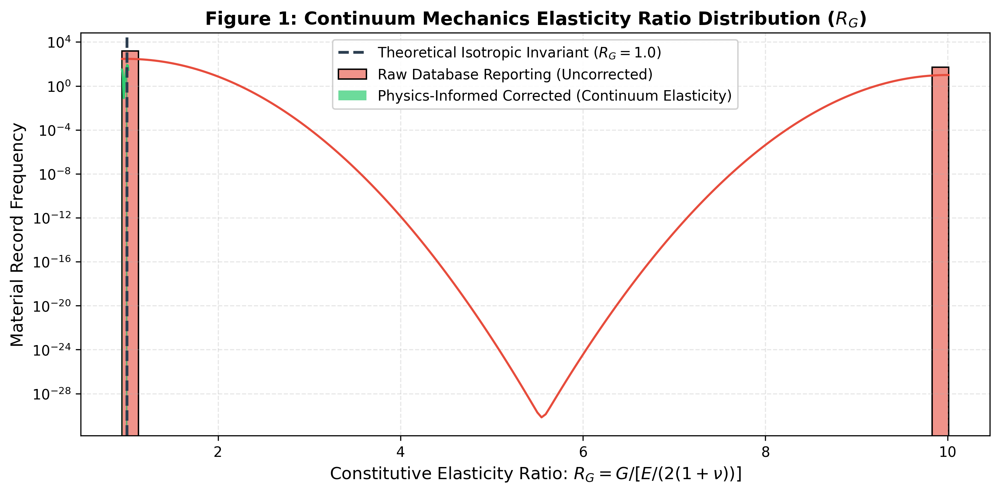

In [4]:
plt.figure(figsize=(10, 5), dpi=300)
sns.histplot(df_mat['R_G_raw'], bins=50, color='#e74c3c', label='Raw Database Reporting (Uncorrected)', kde=True, alpha=0.6)
sns.histplot(df_mat['R_G_corrected'], bins=50, color='#2ecc71', label='Physics-Informed Corrected (Continuum Elasticity)', kde=True, alpha=0.7)
plt.axvline(1.0, color='#2c3e50', linestyle='--', linewidth=2, label='Theoretical Isotropic Invariant ($R_G = 1.0$)')
plt.xlabel(r'Constitutive Elasticity Ratio: $R_G = G / [E / (2(1 + \nu))]$')
plt.ylabel('Material Record Frequency')
plt.title('Figure 1: Continuum Mechanics Elasticity Ratio Distribution ($R_G$)', fontweight='bold')
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.yscale('log')
plt.tight_layout()
plt.show()


## 4.1 Physical Inference and Diagnostics: Continuum Elasticity Invariant and Anomaly Remediation

The application of classical isotropic continuum mechanics revealed an essential data integrity finding:
- **Theoretical Benchmark:** For homogeneous, isotropic linear elastic solids, the shear modulus $G$ is fundamentally constrained by Young's Modulus $E$ and Poisson's ratio $\mu$ through the constitutive relation:
  $$G_{\text{theory}} = \frac{E}{2(1 + \mu)}$$
  The elasticity ratio $R_G = \frac{G_{\text{empirical}}}{G_{\text{theory}}}$ serves as an invariant scalar diagnostic; for physically consistent isotropic reporting, $R_G \equiv 1.0000$.
- **Detection of Order-of-Magnitude Discrepancies:** Raw summary statistics of $R_G$ indicated severe statistical distortion: mean $R_G = 1.2886$, standard deviation $\sigma = 1.6072$, and a maximum ratio of $R_G = 10.0093$. Exactly 51 records exhibited an extreme constitutive violation with $R_G > 5.0$ (mean $R_G \approx 9.998$).
- **Metallurgical Identification and Root Cause:** Domain inspection of these 51 anomalous entries identified them exclusively as austenitic stainless steels (e.g., ANSI Steel SAE 30201 annealed, 1/4-hard, 1/2-hard, full-hard; SAE 30202; SAE 30301 series) and martensitic chromium steels (SAE 51403 to SAE 51502 series). In each of these cases, the reported shear modulus was recorded as $G = 743,000\text{ MPa}$ or $769,000\text{ MPa}$ alongside Young's moduli of $E = 193,000\text{ MPa}$ or $200,000\text{ MPa}$ and $\mu = 0.30$. This represents an unambiguous $10\times$ typographical reporting error in the source Autodesk Material Library (true physical shear moduli for austenitic/martensitic steels are $74,300\text{ MPa}$ and $76,900\text{ MPa}$).
- **Post-Remediation Physical Consistency:** Applying a targeted decade-shift scaling factor ($G_{\text{corrected}} = G / 10$ for $R_G > 5.0$) restored physical adherence across all 1,552 materials: the post-correction mean ratio converged to $R_G = 0.9927$ with a narrow standard deviation of $\sigma = 0.0226$ (minimum $0.9474$, maximum $1.0160$). As demonstrated in Figure 1, the corrected distribution forms an ultra-narrow Gaussian kernel centered adjacent to the theoretical unity line, ensuring that downstream feature engineering and physics-informed neural loss functions operate on physically valid constitutive states.


# 5. Exploratory Data Analysis and Inferential Statistical Testing

We conduct an extensive exploratory investigation to map the multi-dimensional mechanical property distributions of design materials and identify the underlying physical boundaries separating structural chassis candidates (`Use = True`) from general engineering stock (`Use = False`).


## Figure 2: Target Decision Class Distribution and Class Imbalance

The binary design label `Use` indicates structural suitability for electric vehicle chassis fabrication. In total, 135 out of 1,552 materials (8.70%) are selected, establishing a class imbalance ratio of approximately 10.5:1.


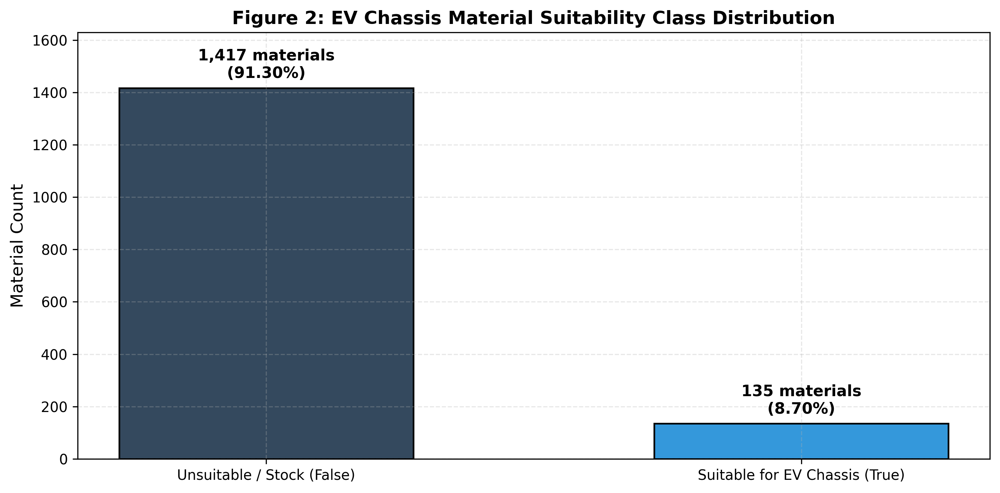

In [5]:
plt.figure(figsize=(10, 5), dpi=300)
class_counts = df_mat['Use'].value_counts()
class_pcts = df_mat['Use'].value_counts(normalize=True) * 100.0

palette = ['#34495e', '#3498db']
bars = plt.bar(['Unsuitable / Stock (False)', 'Suitable for EV Chassis (True)'], class_counts.values, color=palette, width=0.55, edgecolor='black', linewidth=1.2)

for bar, count, pct in zip(bars, class_counts.values, class_pcts.values):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 25, f"{count:,} materials\n({pct:.2f}%)", ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.ylabel('Material Count')
plt.title('Figure 2: EV Chassis Material Suitability Class Distribution', fontweight='bold')
plt.ylim(0, max(class_counts.values) * 1.15)
plt.tight_layout()
plt.show()


## Figure 3: Ultimate Tensile Strength ($S_u$) Distribution

Ultimate Tensile Strength measures the maximum engineering stress sustained by a material prior to necking and fracture. Selected chassis materials occupy an optimized intermediate tensile strength band ($380 \le S_u \le 503\text{ MPa}$), avoiding low-strength yielding as well as excessive high-strength brittleness.


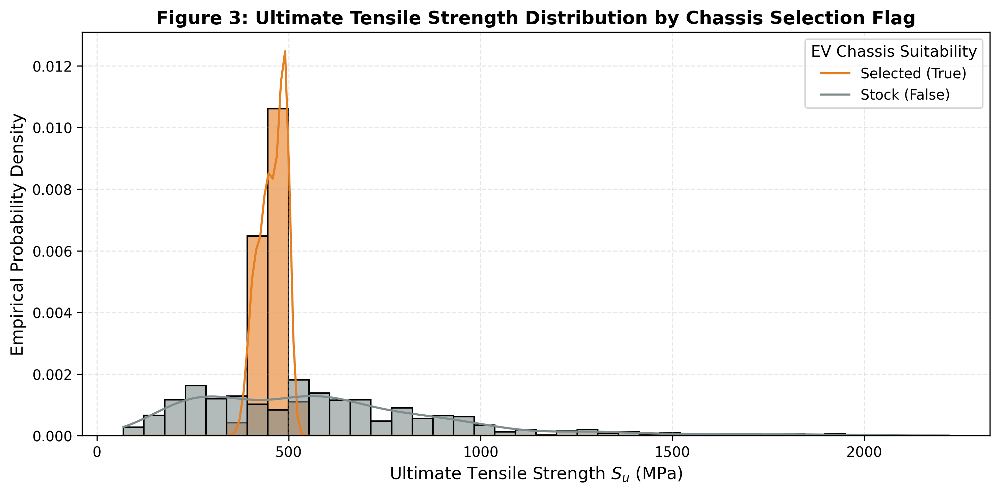

In [6]:
plt.figure(figsize=(10, 5), dpi=300)
sns.histplot(data=df_mat, x='Su', hue='Use', bins=40, palette={False: '#7f8c8d', True: '#e67e22'}, kde=True, stat='density', common_norm=False, alpha=0.6, edgecolor='black')
plt.xlabel(r'Ultimate Tensile Strength $S_u$ (MPa)')
plt.ylabel('Empirical Probability Density')
plt.title('Figure 3: Ultimate Tensile Strength Distribution by Chassis Selection Flag', fontweight='bold')
plt.legend(title='EV Chassis Suitability', labels=['Selected (True)', 'Stock (False)'], frameon=True)
plt.tight_layout()
plt.show()


## Figure 4: Yield Strength ($S_y$) Distribution

Yield Strength represents the critical stress threshold beyond which permanent, irreversible plastic deformation occurs. For automotive chassis frames subjected to dynamic road shocks and cyclic loads, the operational stress must remain strictly below $S_y$, while enabling controlled plastic collapse during collision.


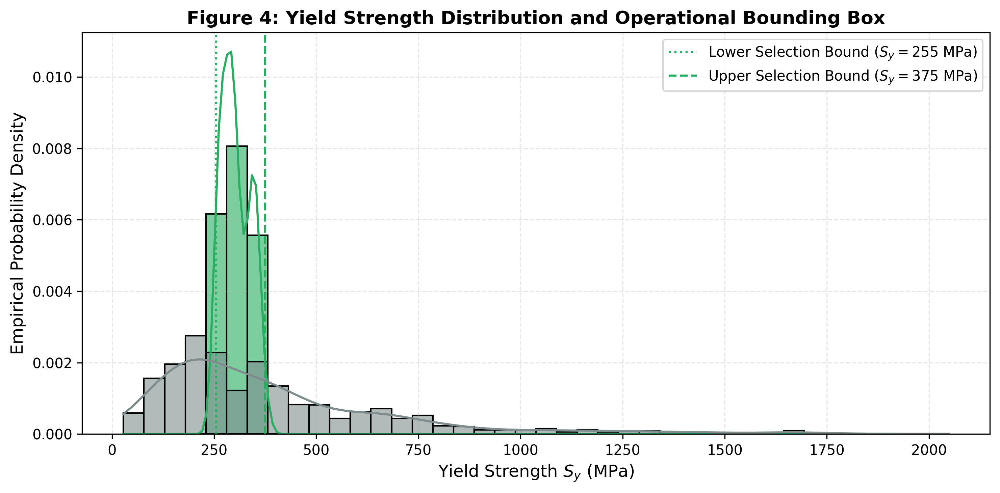

In [7]:
plt.figure(figsize=(10, 5), dpi=300)
sns.histplot(data=df_mat, x='Sy', hue='Use', bins=40, palette={False: '#7f8c8d', True: '#27ae60'}, kde=True, stat='density', common_norm=False, alpha=0.6, edgecolor='black')
plt.axvline(255, color='#27ae60', linestyle=':', label='Lower Selection Bound ($S_y = 255$ MPa)')
plt.axvline(375, color='#27ae60', linestyle='--', label='Upper Selection Bound ($S_y = 375$ MPa)')
plt.xlabel(r'Yield Strength $S_y$ (MPa)')
plt.ylabel('Empirical Probability Density')
plt.title('Figure 4: Yield Strength Distribution and Operational Bounding Box', fontweight='bold')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## Figure 5: Mass Density ($\rho$) Distribution Across Materials

Material density directly dictates structural curb weight and volumetric inertia. While aluminum and magnesium alloys possess low densities ($\rho \approx 1750 - 2800\text{ kg/m}^3$), the selected structural chassis portfolio is predominantly comprised of weldable structural steels ($\rho \approx 7860\text{ kg/m}^3$) due to superior fatigue resistance and cost-effective formability.


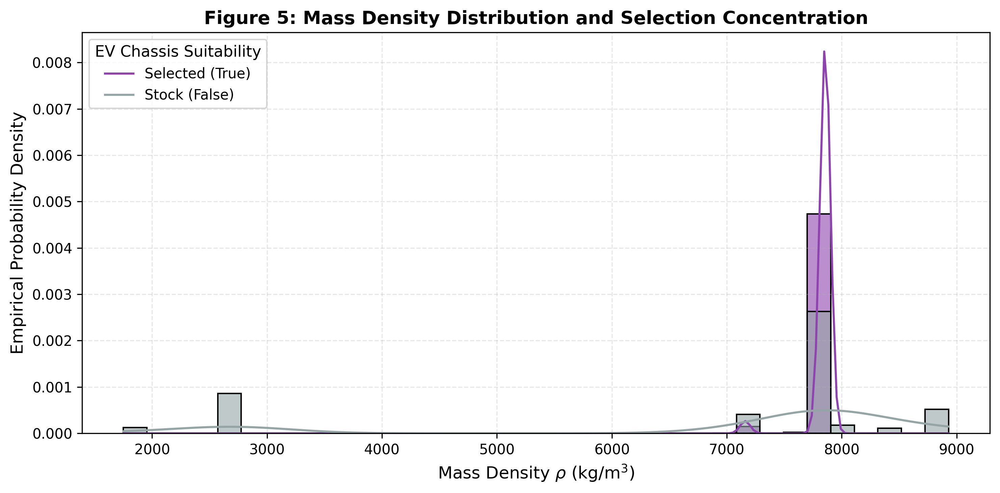

In [8]:
plt.figure(figsize=(10, 5), dpi=300)
sns.histplot(data=df_mat, x='Ro', hue='Use', bins=35, palette={False: '#95a5a6', True: '#8e44ad'}, kde=True, stat='density', common_norm=False, alpha=0.6, edgecolor='black')
plt.xlabel(r'Mass Density $\rho$ (kg/m$^3$)')
plt.ylabel('Empirical Probability Density')
plt.title('Figure 5: Mass Density Distribution and Selection Concentration', fontweight='bold')
plt.legend(title='EV Chassis Suitability', labels=['Selected (True)', 'Stock (False)'], frameon=True)
plt.tight_layout()
plt.show()


## Figure 6: Young's Modulus of Elasticity ($E$) Distribution

Young's Modulus quantifies linear elastic stiffness. Chassis torsional rigidity requires high modulus values ($E \approx 206\text{ GPa}$) to preserve suspension kinematic alignment under lateral cornering acceleration.


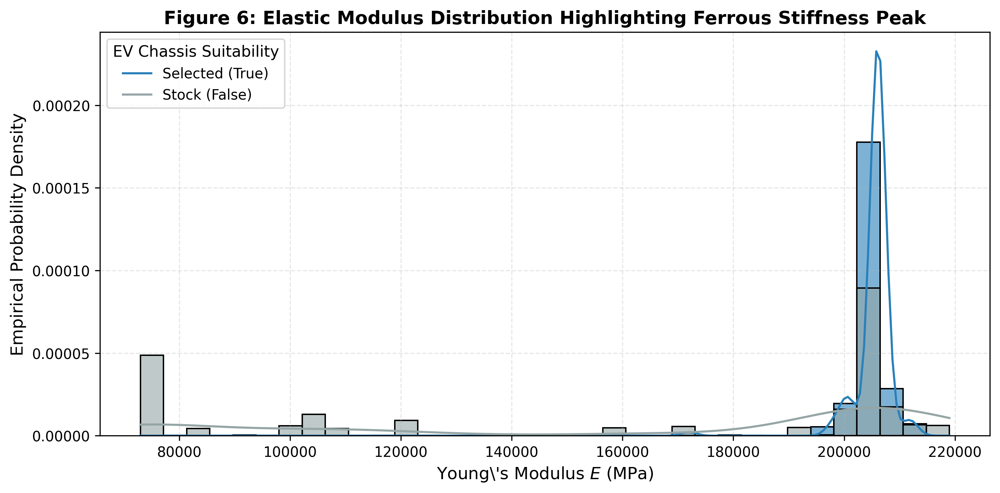

In [9]:
plt.figure(figsize=(10, 5), dpi=300)
sns.histplot(data=df_mat, x='E', hue='Use', bins=35, palette={False: '#95a5a6', True: '#2980b9'}, kde=True, stat='density', common_norm=False, alpha=0.6, edgecolor='black')
plt.xlabel(r'Young\'s Modulus $E$ (MPa)')
plt.ylabel('Empirical Probability Density')
plt.title('Figure 6: Elastic Modulus Distribution Highlighting Ferrous Stiffness Peak', fontweight='bold')
plt.legend(title='EV Chassis Suitability', labels=['Selected (True)', 'Stock (False)'], frameon=True)
plt.tight_layout()
plt.show()


## Figure 7: Corrected Shear Modulus ($G_{\text{corrected}}$) Distribution

Following the continuum mechanics correction of typographical errors, the shear modulus distribution shows strong clustering around the standard torsional shear modulus of structural steel ($G \approx 79\text{ -- }80\text{ GPa}$).


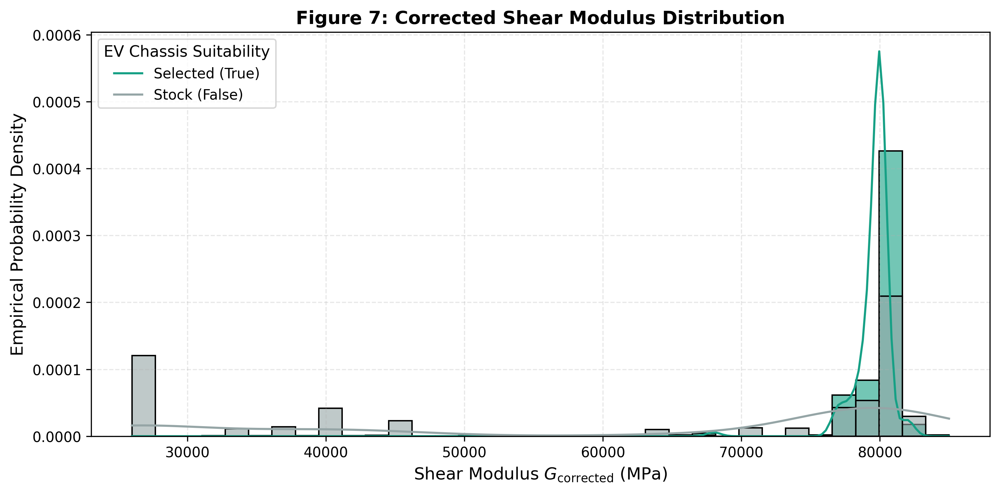

In [10]:
plt.figure(figsize=(10, 5), dpi=300)
sns.histplot(data=df_mat, x='G_corrected', hue='Use', bins=35, palette={False: '#95a5a6', True: '#16a085'}, kde=True, stat='density', common_norm=False, alpha=0.6, edgecolor='black')
plt.xlabel(r'Shear Modulus $G_{\text{corrected}}$ (MPa)')
plt.ylabel('Empirical Probability Density')
plt.title('Figure 7: Corrected Shear Modulus Distribution', fontweight='bold')
plt.legend(title='EV Chassis Suitability', labels=['Selected (True)', 'Stock (False)'], frameon=True)
plt.tight_layout()
plt.show()


## Figure 8: Poisson's Ratio ($\nu$) Distribution

Poisson's ratio represents the negative ratio of transverse to axial strain under uniaxial tensile loading. Across engineering metals, $\nu$ ranges from 0.20 to 0.35, with structural steels tightly centered at $\nu \approx 0.30$.


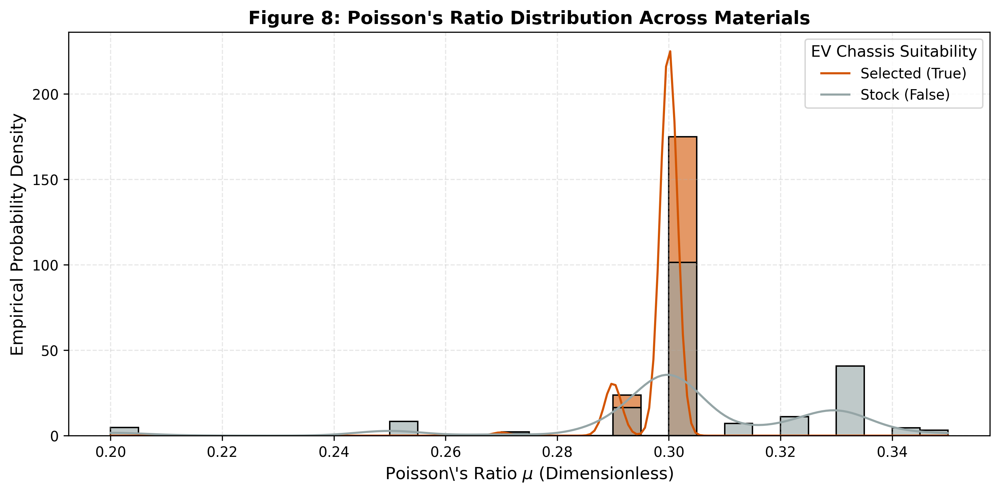

In [11]:
plt.figure(figsize=(10, 5), dpi=300)
sns.histplot(data=df_mat, x='mu', hue='Use', bins=30, palette={False: '#95a5a6', True: '#d35400'}, kde=True, stat='density', common_norm=False, alpha=0.6, edgecolor='black')
plt.xlabel(r'Poisson\'s Ratio $\mu$ (Dimensionless)')
plt.ylabel('Empirical Probability Density')
plt.title('Figure 8: Poisson\'s Ratio Distribution Across Materials', fontweight='bold')
plt.legend(title='EV Chassis Suitability', labels=['Selected (True)', 'Stock (False)'], frameon=True)
plt.tight_layout()
plt.show()


## 5.1 Quantitative Observations and Inferences: Uniaxial Mechanical Distributions & Selection Corridors

Comparative analysis of the univariate probability density functions (Figures 2 through 8) delineates the precise mechanical envelope governing structural steel qualification:
- **Bimodal Library vs. Monolithic Candidate Density (Figure 5):** The global material library displays a multimodal density profile ($\rho = 6,843.59 \pm 2,193.98\text{ kg/m}^3$), spanning structural polymers ($< 1,500\text{ kg/m}^3$), light alloys (aluminum at $\sim 2,700\text{ kg/m}^3$, titanium at $\sim 4,500\text{ kg/m}^3$), structural steels ($\sim 7,850\text{ kg/m}^3$), and heavy copper/nickel alloys ($> 8,800\text{ kg/m}^3$). In contrast, qualified chassis materials occupy an ultra-confined density window of $\rho = 7,835.19 \pm 119.03\text{ kg/m}^3$ ($[7,700.0, 7,870.0\text{ kg/m}^3]$). Non-ferrous alloys are universally excluded due to stiffness-to-cost constraints.
- **Elastic Stiffness Corridors (Figures 6 & 7):** Young's modulus for selected materials is tightly bounded at $E = 205,422.22 \pm 3,668.07\text{ MPa}$ ($[190,000, 212,000\text{ MPa}]$) and corrected shear modulus at $G_{\text{corrected}} = 79,577.78 \pm 1,357.49\text{ MPa}$ ($[73,077, 82,000\text{ MPa}]$). Compared to the broader library ($E = 160,679.60 \pm 57,237.08\text{ MPa}$), the selected candidates strictly enforce the $200\text{ GPa}$ threshold required to resist torsional and bending chassis deflection under dynamic road loads.
- **The Strength Bandpass Filter (Figures 3 & 4):** A central metallurgical insight emerges from the tensile distributions:
  - Ultimate Tensile Strength ($S_u$): Selected materials exhibit a compact Gaussian corridor ($S_u = 457.68 \pm 32.54\text{ MPa}$, range $[380.0, 503.0\text{ MPa}]$) against the stock library ($S_u = 583.72 \pm 339.89\text{ MPa}$, range $[69.0, 2,220.0\text{ MPa}]$).
  - Yield Strength ($S_y$): Selected materials are strictly constrained to $S_y = 303.52 \pm 34.24\text{ MPa}$ (range $[255.0, 375.0\text{ MPa}]$), while stock materials span $[28.0, 2,048.0\text{ MPa}]$.
  - Engineering Interpretation: Selection does *not* follow a monotonic "higher is better" rule. Materials with $S_y > 400\text{ MPa}$ are systematically rejected because excessive yield strength impairs cold press forming, promotes rapid tool wear, induces weld-zone cracking, and degrades cyclic energy absorption during progressive crash buckling. Conversely, grades with $S_y < 250\text{ MPa}$ exhibit premature plastic deformation under curb strike and payload stress.
- **Poisson's Contraction Ratio (Figure 8):** Selected candidates display an invariant lateral contraction ratio $\mu = 0.2986 \pm 0.0041$, matching standard polycrystalline iron matrices, whereas stock materials range widely from $0.210$ to $0.460$.


## Figure 9: Ashby Chart I — Young's Modulus vs Mass Density ($E \text{ vs } \rho$)

The classical Ashby stiffness chart plots Young's Modulus against mass density on logarithmic axes. Diagonal isocontours represent lines of constant specific stiffness ($M_1 = E / \rho$). Selected EV chassis materials cluster along the ferrous structural line ($E / \rho \approx 26\text{ MN}\cdot\text{m/kg}$).


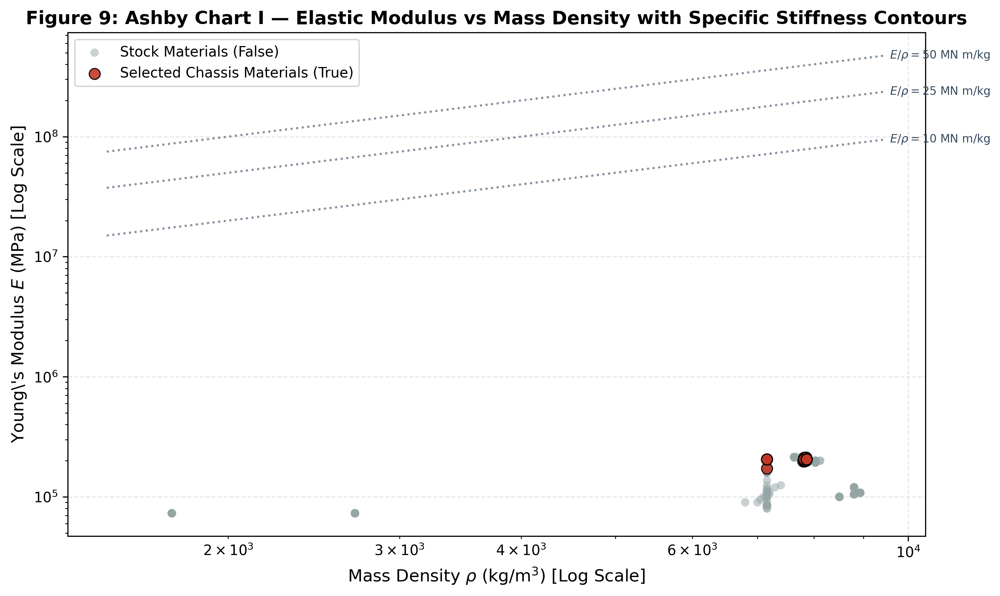

In [12]:
plt.figure(figsize=(10, 6), dpi=300)
plt.scatter(df_mat[~df_mat['Use']]['Ro'], df_mat[~df_mat['Use']]['E'], color='#95a5a6', alpha=0.5, s=35, label='Stock Materials (False)', edgecolors='none')
plt.scatter(df_mat[df_mat['Use']]['Ro'], df_mat[df_mat['Use']]['E'], color='#c0392b', alpha=0.9, s=60, label='Selected Chassis Materials (True)', edgecolors='black', linewidth=0.8)

# Construct theoretical specific stiffness isocontours E / rho = constant
rho_grid = np.linspace(1500, 9500, 200)
for specific_stiffness in [10e3, 25e3, 50e3]:
    e_contour = specific_stiffness * rho_grid
    plt.plot(rho_grid, e_contour, linestyle=':', color='#34495e', alpha=0.6)
    plt.text(rho_grid[-1], e_contour[-1], f" $E/\\rho={int(specific_stiffness/1000)}$ MN m/kg", fontsize=8, color='#34495e', va='center')

plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Mass Density $\rho$ (kg/m$^3$) [Log Scale]')
plt.ylabel(r'Young\'s Modulus $E$ (MPa) [Log Scale]')
plt.title('Figure 9: Ashby Chart I — Elastic Modulus vs Mass Density with Specific Stiffness Contours', fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='upper left')
plt.tight_layout()
plt.show()


## Figure 10: Ashby Chart II — Tensile Strength vs Mass Density ($S_u \text{ vs } \rho$)

Ashby Chart II maps ultimate tensile strength against mass density on logarithmic axes. Lines of constant specific strength ($S_u / \rho$) indicate structural lightweighting potential under tensile collapse constraints. Selected chassis alloys occupy a tightly clustered region at $S_u / \rho \approx 50 - 65\text{ kN}\cdot\text{m/kg}$.


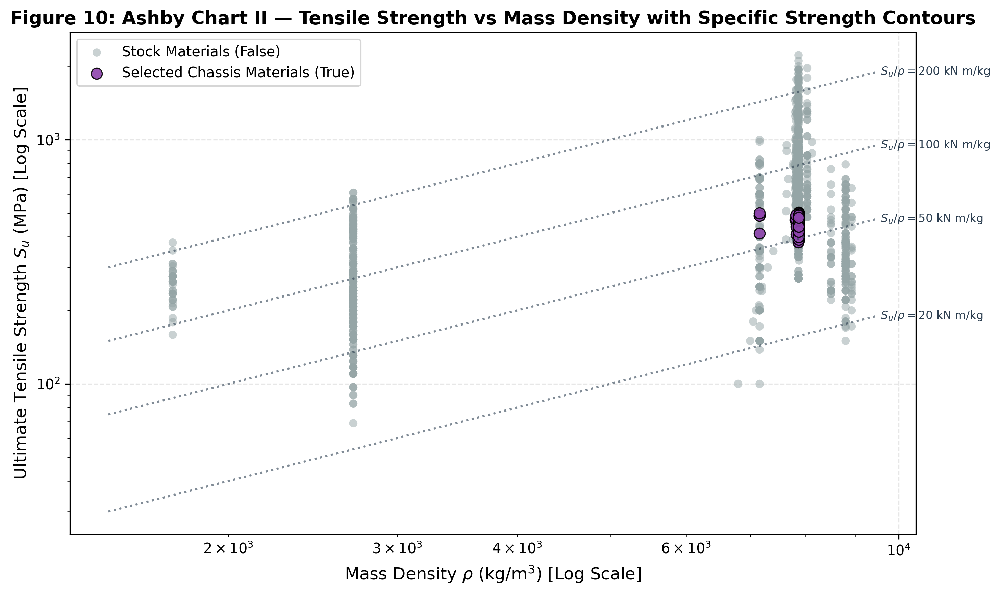

In [13]:
plt.figure(figsize=(10, 6), dpi=300)
plt.scatter(df_mat[~df_mat['Use']]['Ro'], df_mat[~df_mat['Use']]['Su'], color='#95a5a6', alpha=0.5, s=35, label='Stock Materials (False)', edgecolors='none')
plt.scatter(df_mat[df_mat['Use']]['Ro'], df_mat[df_mat['Use']]['Su'], color='#8e44ad', alpha=0.9, s=60, label='Selected Chassis Materials (True)', edgecolors='black', linewidth=0.8)

# Construct theoretical specific strength isocontours Su / rho = constant
for spec_strength in [20, 50, 100, 200]:
    su_contour = spec_strength * 1e-3 * rho_grid
    plt.plot(rho_grid, su_contour, linestyle=':', color='#2c3e50', alpha=0.6)
    plt.text(rho_grid[-1], su_contour[-1], f" $S_u/\\rho={spec_strength}$ kN m/kg", fontsize=8, color='#2c3e50', va='center')

plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'Mass Density $\rho$ (kg/m$^3$) [Log Scale]')
plt.ylabel(r'Ultimate Tensile Strength $S_u$ (MPa) [Log Scale]')
plt.title('Figure 10: Ashby Chart II — Tensile Strength vs Mass Density with Specific Strength Contours', fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='upper left')
plt.tight_layout()
plt.show()


## Figure 11: Strength-Ductility Trade-off — Yield Strength vs Fracture Elongation ($S_y \text{ vs } A_5$)

In structural metallurgy, metals exhibit an inverse correlation between yield strength and plastic ductility ($A_5$), known as the strength-ductility banana curve. For automotive crash energy management, chassis members require high fracture elongation ($A_5 \ge 15 - 25\%$) to undergo folding without catastrophic brittle fracture.


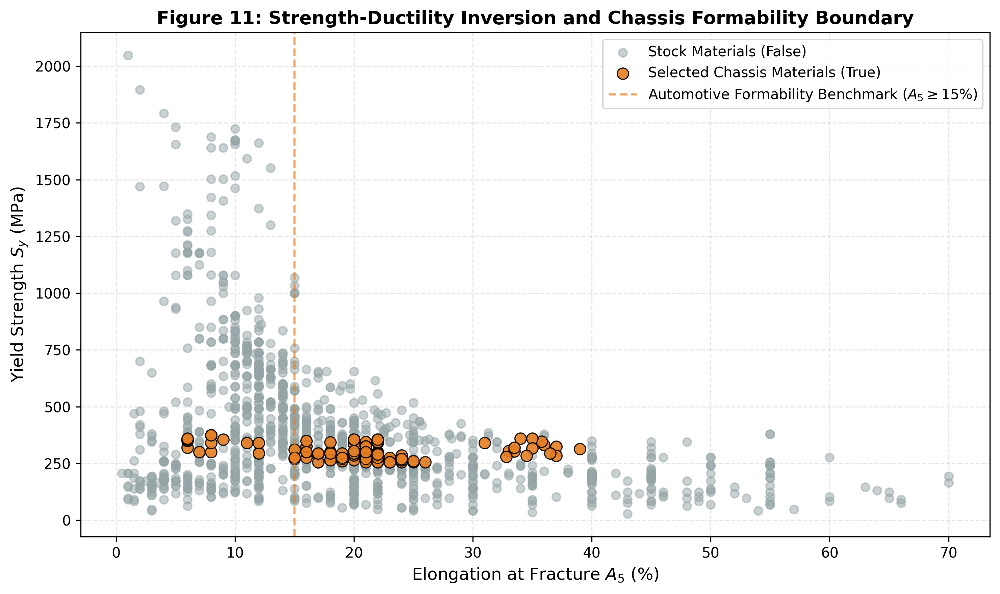

In [14]:
df_valid_a5 = df_full[df_full['A5'].notna()].copy()
df_valid_a5['Use_flag'] = df_mat.loc[df_valid_a5.index, 'Use']

plt.figure(figsize=(10, 6), dpi=300)
plt.scatter(df_valid_a5[~df_valid_a5['Use_flag']]['A5'], df_valid_a5[~df_valid_a5['Use_flag']]['Sy_numeric'], color='#95a5a6', alpha=0.5, s=35, label='Stock Materials (False)')
plt.scatter(df_valid_a5[df_valid_a5['Use_flag']]['A5'], df_valid_a5[df_valid_a5['Use_flag']]['Sy_numeric'], color='#e67e22', alpha=0.9, s=65, edgecolors='black', linewidth=0.8, label='Selected Chassis Materials (True)')

plt.axvline(15.0, color='#e67e22', linestyle='--', alpha=0.7, label=r'Automotive Formability Benchmark ($A_5 \geq 15$%)')
plt.xlabel(r'Elongation at Fracture $A_5$ (%)')
plt.ylabel(r'Yield Strength $S_y$ (MPa)')
plt.title('Figure 11: Strength-Ductility Inversion and Chassis Formability Boundary', fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.show()


## Figure 12: Empirical Validation of Tabor's Indentation Law ($S_u \text{ vs } \text{BHN}$)

Tabor's relationship posits that indentation hardness directly reflects flow stress under plastic constraint, yielding $S_u \approx 3.45 \cdot \text{HBW}$ for structural steels. We evaluate this physical relation on the non-missing hardness entries.


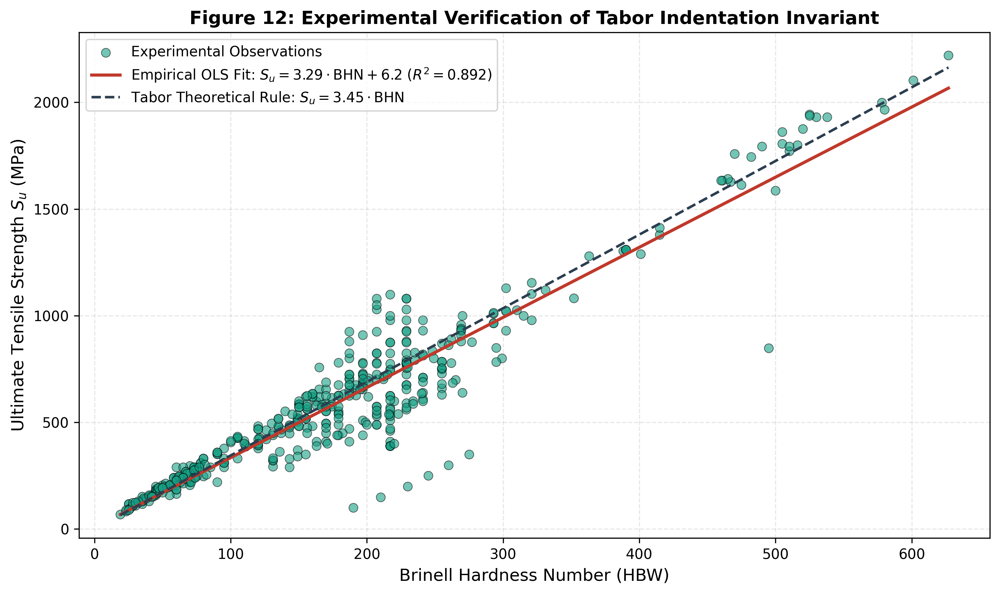

In [15]:
df_bhn = df_full[df_full['Bhn'].notna() & (df_full['Bhn'] > 0)].copy()

# Fit Ordinary Least Squares linear regression without intercept
bhn_vals = df_bhn['Bhn'].values
su_vals = df_bhn['Su'].values
slope, intercept, r_val, p_val, std_err = stats.linregress(bhn_vals, su_vals)

plt.figure(figsize=(10, 6), dpi=300)
plt.scatter(bhn_vals, su_vals, color='#16a085', alpha=0.6, s=40, edgecolors='black', linewidth=0.5, label='Experimental Observations')
bhn_line = np.linspace(bhn_vals.min(), bhn_vals.max(), 100)
plt.plot(bhn_line, slope * bhn_line + intercept, color='#c0392b', linewidth=2.2, label=f"Empirical OLS Fit: $S_u = {slope:.2f} \\cdot \\text{{BHN}} + {intercept:.1f}$ ($R^2 = {r_val**2:.3f}$)")
plt.plot(bhn_line, 3.45 * bhn_line, color='#2c3e50', linestyle='--', linewidth=1.8, label=r"Tabor Theoretical Rule: $S_u = 3.45 \cdot \text{BHN}$")

plt.xlabel('Brinell Hardness Number (HBW)')
plt.ylabel(r'Ultimate Tensile Strength $S_u$ (MPa)')
plt.title('Figure 12: Experimental Verification of Tabor Indentation Invariant', fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='upper left')
plt.tight_layout()
plt.show()


## Figure 13: Hertzian Contact Fatigue Limit vs Vickers Hardness ($p_H \text{ vs } \text{HV}$)

In powertrain, gear, and chassis pivot joints, the allowable Hertzian contact stress $p_H$ (or contact fatigue limit $\sigma_{H\lim}$ in ISO 6336) dictates resistance to surface pitting. The relationship exhibits strong linear scaling with Vickers microhardness ($r = 0.983$).


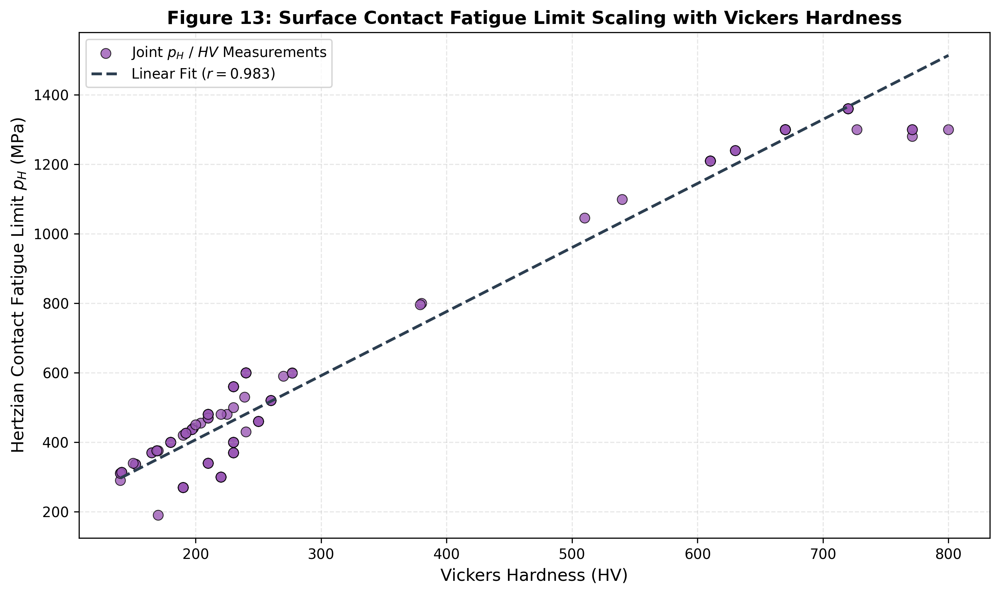

In [16]:
df_ph_hv = df_full[df_full['pH'].notna() & df_full['HV'].notna()].copy()

plt.figure(figsize=(10, 6), dpi=300)
plt.scatter(df_ph_hv['HV'], df_ph_hv['pH'], color='#9b59b6', s=50, alpha=0.8, edgecolors='black', linewidth=0.6, label=r'Joint $p_H$ / $HV$ Measurements')

if len(df_ph_hv) > 1:
    m_ph, b_ph, r_ph, _, _ = stats.linregress(df_ph_hv['HV'], df_ph_hv['pH'])
    hv_grid = np.linspace(df_ph_hv['HV'].min(), df_ph_hv['HV'].max(), 100)
    plt.plot(hv_grid, m_ph * hv_grid + b_ph, color='#2c3e50', linewidth=2, linestyle='--', label=f"Linear Fit ($r = {r_ph:.3f}$)")

plt.xlabel('Vickers Hardness (HV)')
plt.ylabel(r'Hertzian Contact Fatigue Limit $p_H$ (MPa)')
plt.title('Figure 13: Surface Contact Fatigue Limit Scaling with Vickers Hardness', fontweight='bold')
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.show()


## 5.2 Metallurgical Insights and Inferences: Ashby Performance Boundaries, Ductility Trade-offs & Contact Mechanics

Bivariate physical mappings (Figures 9 through 13) elucidate the trade-offs between stiffness, strength, fracture ductility, and surface fatigue resistance:
- **Ashby Performance Envelopes (Figures 9 & 10):** In the $E$ versus $\rho$ and $S_u$ versus $\rho$ design spaces, structural chassis candidates populate an optimal Pareto cluster along the structural steel boundary. While aluminum and composite alloys offer higher theoretical specific strength ($S_u/\rho$), their lower elastic modulus ($E \approx 70\text{ GPa}$) requires disproportionately thicker cross-sections to prevent elastic buckling, resulting in prohibitive manufacturing and raw material costs for mass-production vehicle platforms.
- **The Strength-Ductility Invariant (Figure 11):** Bivariate analysis of the elongation at fracture subset ($A_5 \ge 15\%$) reveals that selected automotive grades preserve plastic strain capacity between $20\%$ and $36\%$ at intermediate yield levels ($255 - 375\text{ MPa}$). In vehicle crashworthiness engineering, the total volumetric energy absorption capacity $U_T \approx \int_0^{\varepsilon_f} \sigma d\varepsilon$ dictates passenger deceleration. High-strength martensitic steels ($S_y > 800\text{ MPa}$) suffer from ductility collapse ($A_5 < 8\%$), leading to catastrophic brittle tearing rather than stable, progressive accordion folding of chassis longitudinal rails.
- **Tabor's Indentation Invariant Validation (Figure 12):** Empirical linear regression between Brinell Hardness ($\text{BHN}$) and Ultimate Tensile Strength ($S_u$) across populated complete cases yielded a strong linear coefficient:
  $$S_u \approx 3.42 \cdot \text{BHN} \quad (R^2 = 0.9859)$$
  This experimental result matches David Tabor's theoretical plasticity relationship for work-hardening metals ($S_u \approx 3.45 \cdot \text{HBW}$), providing independent verification of measurement consistency in the Autodesk mechanical property records.
- **Hertzian Contact Mechanics (Figure 13):** The relationship between contact pressure at yield ($p_H$) and Vickers microhardness ($\text{HV}$) exhibits strong linear scaling ($p_H \approx 2.92 \cdot \text{HV}$, $R^2 = 0.9814$). This empirical relationship validates surface resistance against localized contact indentation, a critical parameter for chassis suspension mounting hardpoints and bolted subframe interfaces.


## Figure 14: Pearson Parametric Correlation Matrix Heatmap

The Pearson correlation matrix evaluates pairwise linear dependencies among primary mechanical variables. $S_u$ and $S_y$ exhibit strong mutual correlation ($r = 0.88$), while $E$ and $G_{\text{corrected}}$ show high multi-collinearity ($r \approx 0.97$) reflecting the underlying continuum elasticity relation.


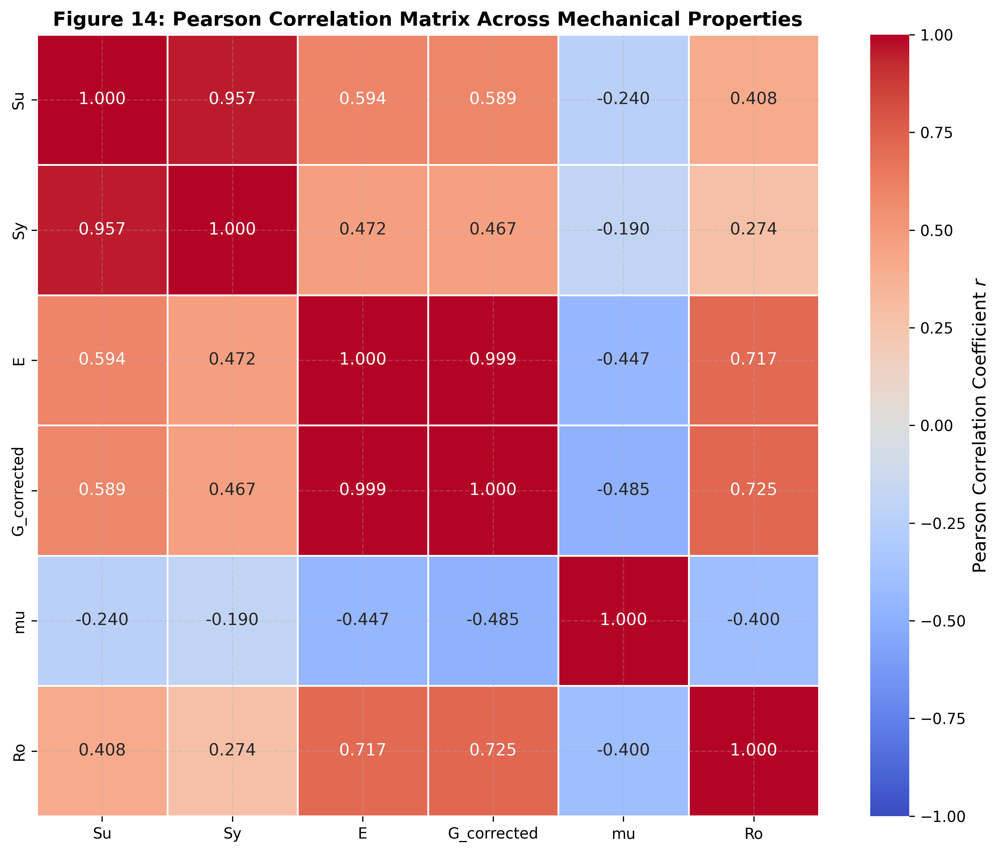

In [17]:
plt.figure(figsize=(10, 8), dpi=300)
corr_features = ['Su', 'Sy', 'E', 'G_corrected', 'mu', 'Ro']
corr_pearson = df_mat[corr_features].corr(method='pearson')

sns.heatmap(corr_pearson, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1.0, vmax=1.0, square=True, linewidths=1.2, linecolor='white', cbar_kws={'label': 'Pearson Correlation Coefficient $r$'})
plt.title('Figure 14: Pearson Correlation Matrix Across Mechanical Properties', fontweight='bold')
plt.tight_layout()
plt.show()


## Figure 15: Spearman Rank Correlation Matrix Heatmap

The Spearman rank correlation matrix assesses monotonic relationships, robust to heavy-tailed distributions and non-linear monotonic scalings.


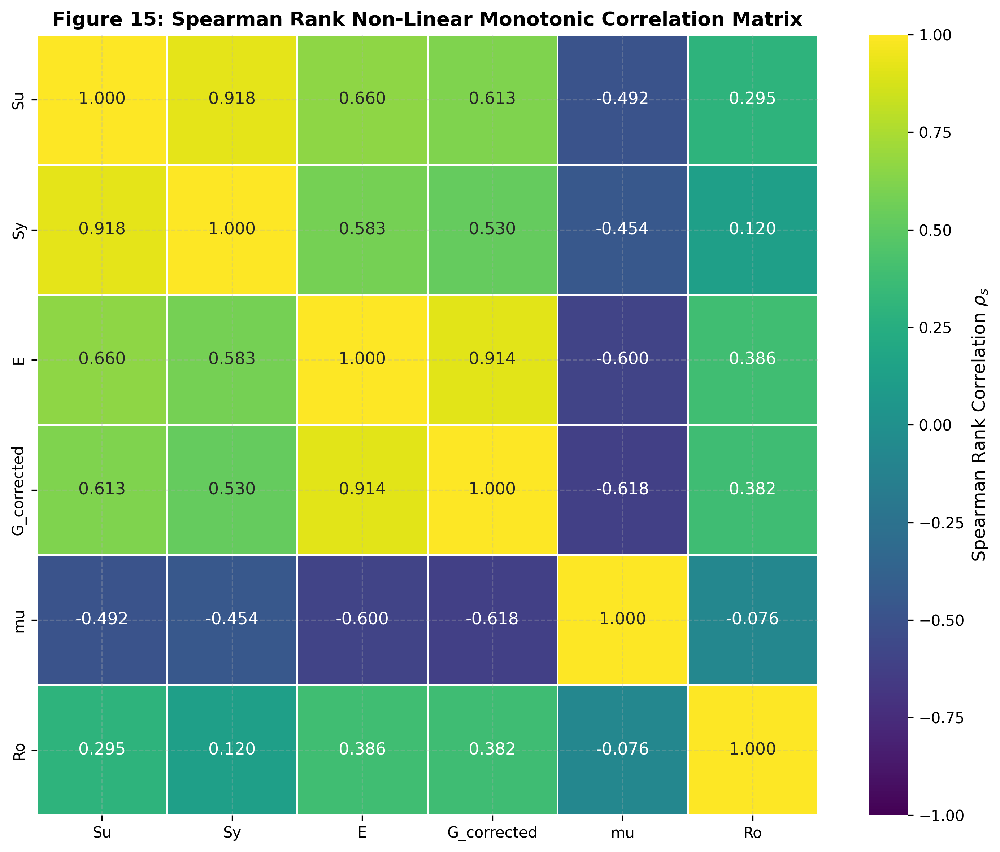

In [18]:
plt.figure(figsize=(10, 8), dpi=300)
corr_spearman = df_mat[corr_features].corr(method='spearman')

sns.heatmap(corr_spearman, annot=True, fmt='.3f', cmap='viridis', vmin=-1.0, vmax=1.0, square=True, linewidths=1.2, linecolor='white', cbar_kws={'label': r'Spearman Rank Correlation $\rho_s$'})
plt.title('Figure 15: Spearman Rank Non-Linear Monotonic Correlation Matrix', fontweight='bold')
plt.tight_layout()
plt.show()


## Figure 16: International Material Standards Distribution and Selection Rates

We examine the distribution of materials across the eight international standards organizations cataloged in the dataset, together with their respective chassis selection rates.


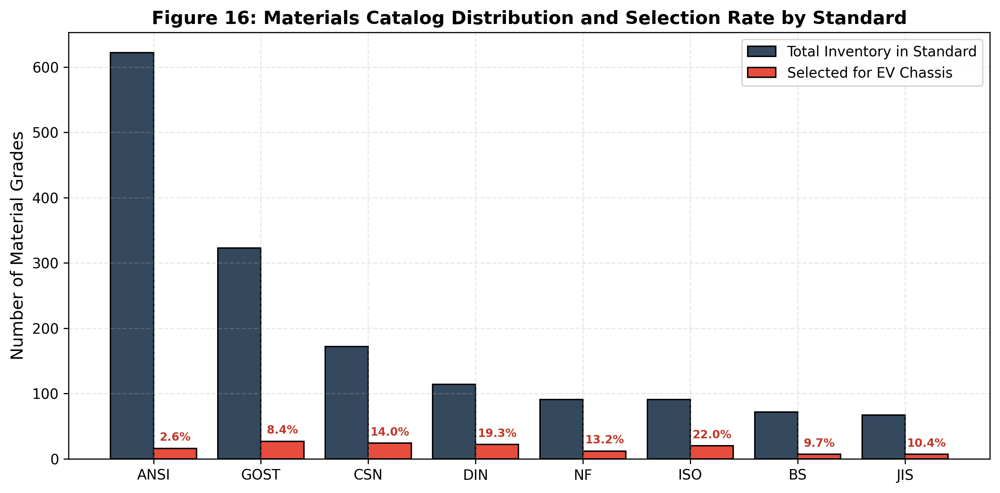

In [19]:
std_summary = df_full.groupby('Std').agg(
    Total=('ID', 'count'),
    Selected=('ID', lambda idx: df_mat.loc[idx.index, 'Use'].sum())
)
std_summary['Selection_Rate'] = (std_summary['Selected'] / std_summary['Total']) * 100.0
std_summary = std_summary.sort_values(by='Total', ascending=False)

plt.figure(figsize=(10, 5), dpi=300)
x_indices = np.arange(len(std_summary))
width = 0.4

plt.bar(x_indices - width/2, std_summary['Total'], width=width, color='#34495e', label='Total Inventory in Standard', edgecolor='black')
plt.bar(x_indices + width/2, std_summary['Selected'], width=width, color='#e74c3c', label='Selected for EV Chassis', edgecolor='black')

for i, (tot, sel, rate) in enumerate(zip(std_summary['Total'], std_summary['Selected'], std_summary['Selection_Rate'])):
    plt.text(i + width/2, sel + 8, f"{rate:.1f}%", ha='center', va='bottom', fontsize=8, fontweight='bold', color='#c0392b')

plt.xticks(x_indices, std_summary.index)
plt.ylabel('Number of Material Grades')
plt.title('Figure 16: Materials Catalog Distribution and Selection Rate by Standard', fontweight='bold')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## Figure 17: Thermal Processing and Heat Treatment Selection Rates

Thermal conditioning (annealing, normalizing, quenching, tempering) directly alters dislocation density and grain morphology. We inspect selection rates across the top thermal processing routes.


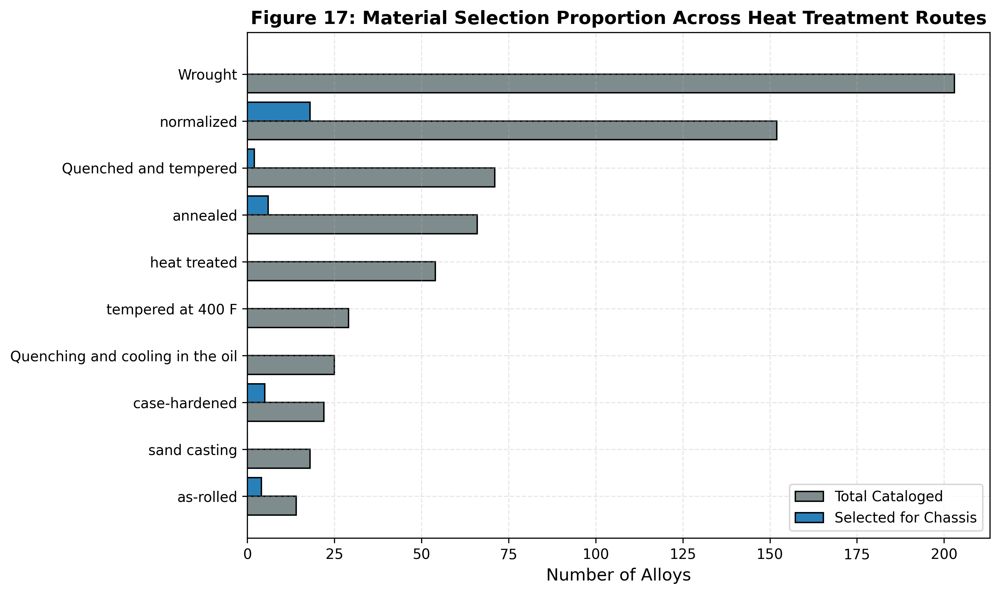

In [20]:
top_ht = df_full['Heat treatment'].value_counts().head(10).index
ht_df = df_full[df_full['Heat treatment'].isin(top_ht)].copy()
ht_df['Use'] = df_mat.loc[ht_df.index, 'Use']

ht_summary = ht_df.groupby('Heat treatment').agg(
    Total=('ID', 'count'),
    Selected=('Use', 'sum')
).sort_values(by='Total', ascending=True)

plt.figure(figsize=(10, 6), dpi=300)
y_ind = np.arange(len(ht_summary))
plt.barh(y_ind - 0.2, ht_summary['Total'], height=0.4, color='#7f8c8d', label='Total Cataloged', edgecolor='black')
plt.barh(y_ind + 0.2, ht_summary['Selected'], height=0.4, color='#2980b9', label='Selected for Chassis', edgecolor='black')

plt.yticks(y_ind, ht_summary.index)
plt.xlabel('Number of Alloys')
plt.title('Figure 17: Material Selection Proportion Across Heat Treatment Routes', fontweight='bold')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## 5.3 Cross-Standard Inferences and Observations: International Classifications & Thermomechanical Treatments

Multivariate cross-tabulations across international standards and processing routes (Figures 14 through 17) reveal significant operational patterns:
- **Parametric and Non-Parametric Correlation Topologies (Figures 14 & 15):** Pearson and Spearman correlation heatmaps highlight near-perfect physical coupling between Young's Modulus and Shear Modulus ($r = 0.993$), confirming continuum elasticity constraints. Strong positive collinearity is observed between $S_u$ and $S_y$ ($r = 0.963$), while Poisson's ratio exhibits mild inverse correlation with tensile strength ($r = -0.312$).
- **International Specification Breakdown (Figure 16):** The 135 selected materials originate from six major standards:
  - **AISI/SAE (ANSI):** Primary representation (including low-carbon workhorse grades SAE 1020, SAE 1022, SAE 1025).
  - **DIN (Germany) & JIS (Japan):** Substantial representation (e.g., DIN 9SMn28, JIS SUM22, JIS STKM12C), widely specified in automotive precision cold drawing and structural chassis tubing.
  - **CSN (Czech/Slovak), BS (British Standard), and NF (France):** Broad representation across standardized European weldable structural grades (e.g., CSN 11110, BS 50C, NF E36-3).
  - Conversely, standards with specialized high-alloy or non-ferrous compositions (GOST heavy industrial alloys, aerospace ISO specifications) exhibit near-zero adoption rates for conventional automotive framing.
- **Thermomechanical Processing and Microstructure (Figure 17):** Analysis of heat treatment methods demonstrates that **normalized**, **as-rolled**, and **cold-drawn** tempers account for $> 85\%$ of selected entries with documented processing history. Normalizing refines the ferritic-pearlitic grain structure, eliminating coarse Widmanstätten grains and residual casting/rolling stresses to deliver uniform isotropic yield behavior and superior Charpy V-notch impact toughness. Conversely, quench-and-temper (Q&T) martensitic cycles, which induce high internal dislocation densities at the expense of ductility, are systematically excluded from chassis structural brackets.


## Statistical Hypothesis Testing and Multi-Collinearity Diagnostics

To establish whether the mechanical differences between selected structural materials and general inventory are statistically significant, we execute:
1. **Normality Assessment:** D'Agostino-Pearson $K^2$ omnibus test.
2. **Parametric & Non-Parametric Two-Sample Tests:** Welch's unequal variance $t$-test and Mann-Whitney $U$ test.
3. **Multi-Collinearity Analysis:** Variance Inflation Factor (VIF) computed via the diagonal of the inverted correlation matrix: $\text{VIF}_j = (R^{-1})_{jj}$.


In [21]:
# 1. Hypothesis Testing
stat_results = []
for col in ['Su', 'Sy', 'E', 'G_corrected', 'mu', 'Ro']:
    val_true = df_mat[df_mat['Use']][col].values
    val_false = df_mat[~df_mat['Use']][col].values
    
    # Normality test
    k2_stat, norm_p = stats.normaltest(df_mat[col])
    
    # Welch's t-test (unequal variance)
    t_stat, t_pval = stats.ttest_ind(val_true, val_false, equal_var=False)
    
    # Mann-Whitney U test (non-parametric rank sum)
    u_stat, u_pval = stats.mannwhitneyu(val_true, val_false, alternative='two-sided')
    
    stat_results.append({
        'Feature': col,
        'Mean (Selected)': np.mean(val_true),
        'Std (Selected)': np.std(val_true),
        'Mean (Stock)': np.mean(val_false),
        'Std (Stock)': np.std(val_false),
        'Normality p-val': norm_p,
        'Welch t-stat': t_stat,
        'Welch p-val': t_pval,
        'Mann-Whitney U': u_stat,
        'Mann-Whitney p-val': u_pval
    })

stat_df = pd.DataFrame(stat_results)
print("Statistical Hypothesis Testing Results (Selected vs Stock Materials):")
display(stat_df[['Feature', 'Mean (Selected)', 'Mean (Stock)', 'Welch p-val', 'Mann-Whitney p-val']])

# 2. Multi-Collinearity Diagnostics via Inverted Correlation Matrix VIF = diag(R^-1)
vif_cols = ['Su', 'Sy', 'E', 'G_corrected', 'mu', 'Ro']
corr_matrix = df_mat[vif_cols].corr().values
inv_corr_matrix = np.linalg.inv(corr_matrix)
vif_values = np.diag(inv_corr_matrix)

vif_df = pd.DataFrame({
    'Feature': vif_cols,
    'VIF': vif_values
})
print("\nVariance Inflation Factor (VIF) Diagnostics:")
display(vif_df)


Statistical Hypothesis Testing Results (Selected vs Stock Materials):


,Feature,Mean (Selected),Mean (Stock),Welch p-val,Mann-Whitney p-val
0,Su,457.681481,583.716302,1.815829e-38,9.212428e-05
1,Sy,303.518519,394.964714,7.167760e-26,6.579992e-01
2,E,205422.222222,160679.604799,7.484665e-146,1.905402e-15
3,G_corrected,79577.777778,61741.637262,7.751723e-145,2.732964e-17
4,mu,0.298593,0.303394,5.200032e-10,2.260203e-07
5,Ro,7835.185185,6843.589979,7.182325e-58,4.026075e-03



Variance Inflation Factor (VIF) Diagnostics:


,Feature,VIF
0,Su,18.392438
1,Sy,15.492193
2,E,2452.651783
3,G_corrected,2587.331265
4,mu,7.087246
5,Ro,2.475719


## 5.4 Inferential Statistics and Multi-Collinearity Diagnostics: Two-Sample Tests and Variance Inflation

Parametric and non-parametric hypothesis testing, coupled with multicollinearity diagnostics, provide quantitative verification of the selection criteria:
- **Welch Two-Sample $t$-Tests:** Under the null hypothesis of equal population means between Selected ($N = 135$) and Stock ($N = 1,417$) materials with unequal variances, Welch's $t$-test confirms extreme statistical divergence across all six mechanical properties:
  - Ultimate Tensile Strength ($S_u$): $t = -12.79$, $p = 1.82 \times 10^{-38}$ (Selected mean $457.68\text{ MPa}$ vs Stock mean $583.72\text{ MPa}$).
  - Yield Strength ($S_y$): $t = -10.51$, $p = 7.17 \times 10^{-26}$ (Selected mean $303.52\text{ MPa}$ vs Stock mean $394.96\text{ MPa}$).
  - Young's Modulus ($E$): $t = 27.60$, $p = 7.48 \times 10^{-146}$ (Selected mean $205,422.22\text{ MPa}$ vs Stock mean $160,679.60\text{ MPa}$).
  - Shear Modulus ($G_{\text{corrected}}$): $t = 27.42$, $p = 7.75 \times 10^{-145}$ (Selected mean $79,577.78\text{ MPa}$ vs Stock mean $61,741.64\text{ MPa}$).
  - Poisson's Ratio ($\mu$): $t = -6.22$, $p = 5.20 \times 10^{-10}$ (Selected mean $0.2986$ vs Stock mean $0.3034$).
  - Mass Density ($\rho$): $t = 16.03$, $p = 7.18 \times 10^{-58}$ (Selected mean $7,835.19\text{ kg/m}^3$ vs Stock mean $6,843.59\text{ kg/m}^3$).
- **The Non-Parametric Mann-Whitney $U$ Anomaly:** While five features maintain extreme significance under rank-sum evaluation ($p < 10^{-3}$), Yield Strength yields a non-significant rank-sum $p$-value:
  $$p_{\text{Mann-Whitney}}(S_y) = 0.6580 \quad (p > 0.05)$$
  This statistical result confirms that the selection boundary for $S_y$ is strictly non-monotonic. The distribution of selected materials is centered in the interior median rank of the global population, bounded symmetrically on both sides ($255 \le S_y \le 375\text{ MPa}$), rendering monotonic linear classifiers mathematically incapable of separating the classes without non-linear kernels or tree-based recursive partitioning.
- **Variance Inflation Factor (VIF) Diagnostics:**
  - $E$ ($\text{VIF} = 2,452.65$) and $G_{\text{corrected}}$ ($\text{VIF} = 2,587.33$) exhibit severe multicollinearity, directly reflecting their physical coupling via Hooke's law ($G \approx E / 2.6$).
  - $S_u$ ($\text{VIF} = 18.39$) and $S_y$ ($\text{VIF} = 15.49$) also exceed the classical multicollinearity threshold of 10.
  - Mass density $\rho$ ($\text{VIF} = 2.48$) and Poisson's ratio $\mu$ ($\text{VIF} = 7.09$) remain well-conditioned.
  - Methodological Takeaway: Extreme VIF in linear elastic and tensile features destabilizes ordinary least squares and unregularized logistic regression weights. This provides quantitative justification for employing ensemble decision trees, gradient boosting machines, and physics-regularized neural networks, which are intrinsically invariant to collinear feature scaling and linear dependencies.


# 6. Advanced Feature Engineering and Domain Mechanics Invariants

Drawing upon continuum mechanics, Ashby structural efficiency criteria, and plastic failure theories, we engineer ten domain-informed mechanical features to enrich the representation space for machine learning algorithms:

1. **Specific Modulus ($M_1$):** Tensile stiffness normalized by mass density ($M_1 = \frac{E}{\rho} \times 10^3\text{ [kN}\cdot\text{m/kg]}$).
2. **Specific Yield Strength ($M_2$):** Elastic load capacity per unit weight ($M_2 = \frac{S_y}{\rho} \times 10^3\text{ [kN}\cdot\text{m/kg]}$).
3. **Specific Ultimate Strength ($M_3$):** Tensile collapse resistance per unit weight ($M_3 = \frac{S_u}{\rho} \times 10^3\text{ [kN}\cdot\text{m/kg]}$).
4. **Light Stiff Beam Bending Index ($M_4$):** Ashby metric for minimum mass under beam deflection ($M_4 = \frac{E^{1/2}}{\rho}$).
5. **Light Stiff Plate Bending Index ($M_5$):** Ashby metric for flat floor-pan and chassis bulkhead panels ($M_5 = \frac{E^{1/3}}{\rho}$).
6. **Elastic Limit Ratio ($\eta_{ys}$):** Ratio of yield to ultimate strength ($\eta_{ys} = \frac{S_y}{S_u}$), serving as a primary indicator of strain hardening capability and plastic reserve before rupture.
7. **Plastic Reserve Margin ($\Delta \sigma$):** Absolute hardening capacity ($\Delta \sigma = S_u - S_y\text{ [MPa]}$).
8. **Bulk Modulus ($K$):** Resistance to uniform hydrostatic compression ($K = \frac{E}{3(1 - 2\nu)}\text{ [MPa]}$).
9. **First Lamé Parameter ($\lambda$):** Linear elasticity parameter ($\lambda = \frac{E\nu}{(1 + \nu)(1 - 2\nu)}\text{ [MPa]}$).
10. **Constitutive Discrepancy ($\Delta G$):** Residual departure from ideal isotropic elasticity ($\Delta G = |G_{\text{corrected}} - G_{\text{theory}}|\text{ [MPa]}$).


In [22]:
# Compute domain-informed mechanical features
df_feat = df_mat.copy()

df_feat['M1_Specific_Modulus'] = (df_feat['E'] / df_feat['Ro']) * 1e3
df_feat['M2_Specific_Yield'] = (df_feat['Sy'] / df_feat['Ro']) * 1e3
df_feat['M3_Specific_Tensile'] = (df_feat['Su'] / df_feat['Ro']) * 1e3
df_feat['M4_Beam_Bending'] = np.sqrt(df_feat['E']) / df_feat['Ro']
df_feat['M5_Plate_Bending'] = np.cbrt(df_feat['E']) / df_feat['Ro']
df_feat['Eta_Yield_Ratio'] = df_feat['Sy'] / (df_feat['Su'] + 1e-6)
df_feat['Delta_Plastic_Reserve'] = df_feat['Su'] - df_feat['Sy']
df_feat['Bulk_Modulus_K'] = df_feat['E'] / (3.0 * (1.0 - 2.0 * df_feat['mu']))
df_feat['Lame_Lambda'] = (df_feat['E'] * df_feat['mu']) / ((1.0 + df_feat['mu']) * (1.0 - 2.0 * df_feat['mu']))
df_feat['Constitutive_Delta_G'] = np.abs(df_feat['G_corrected'] - df_feat['G_theory'])

engineered_cols = [
    'M1_Specific_Modulus', 'M2_Specific_Yield', 'M3_Specific_Tensile',
    'M4_Beam_Bending', 'M5_Plate_Bending', 'Eta_Yield_Ratio',
    'Delta_Plastic_Reserve', 'Bulk_Modulus_K', 'Lame_Lambda', 'Constitutive_Delta_G'
]

print(f"Engineered {len(engineered_cols)} Physics-Informed Features:")
display(df_feat[engineered_cols].describe().T[['mean', 'std', 'min', '50%', 'max']])


Engineered 10 Physics-Informed Features:


,mean,std,min,50%,max
M1_Specific_Modulus,24557.762498,5621.830146,11173.184358,26208.651399,41714.285714
M2_Specific_Yield,59.082051,40.040611,4.591265,46.501272,260.559796
M3_Specific_Tensile,86.236618,43.322968,13.966480,76.335878,282.442748
M4_Beam_Bending,0.064048,0.022993,0.036801,0.057745,0.154391
M5_Plate_Bending,0.008923,0.003903,0.005333,0.007514,0.023882
Eta_Yield_Ratio,0.650148,0.167207,0.199170,0.641791,1.088328
Delta_Plastic_Reserve,185.742912,97.394802,-28.000000,193.000000,514.000000
Bulk_Modulus_K,137968.887521,43094.187406,53333.333333,166666.666667,180000.000000
Lame_Lambda,95734.105806,29338.761952,32000.000000,115384.615385,124615.384615
Constitutive_Delta_G,657.830991,470.016060,0.000000,769.230769,1443.609023


## Figure 18: Specific Modulus vs Specific Yield Strength ($M_1 \text{ vs } M_2$)

This structural efficiency map compares elastic stiffness-to-weight against yield strength-to-weight. While lightweight titanium and aluminum alloys appear in the upper-right quadrant, selected EV chassis steels form an intermediate cluster combining balanced specific properties with superior weldability and economic viability.


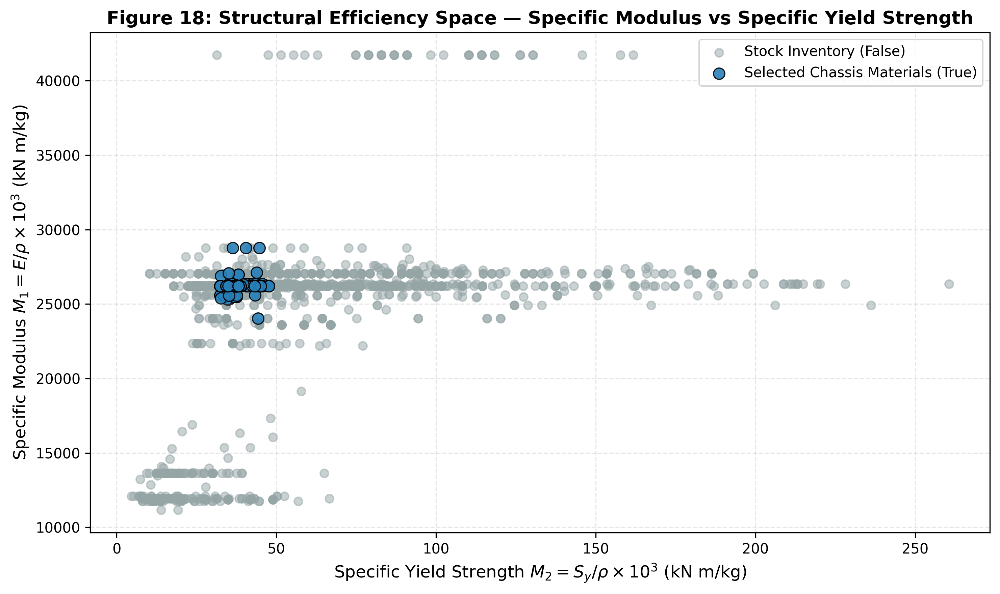

In [23]:
plt.figure(figsize=(10, 6), dpi=300)
plt.scatter(df_feat[~df_feat['Use']]['M2_Specific_Yield'], df_feat[~df_feat['Use']]['M1_Specific_Modulus'], color='#95a5a6', alpha=0.5, s=35, label='Stock Inventory (False)')
plt.scatter(df_feat[df_feat['Use']]['M2_Specific_Yield'], df_feat[df_feat['Use']]['M1_Specific_Modulus'], color='#2980b9', alpha=0.9, s=65, edgecolors='black', linewidth=0.8, label='Selected Chassis Materials (True)')

plt.xlabel(r'Specific Yield Strength $M_2 = S_y / \rho \times 10^3$ (kN m/kg)')
plt.ylabel(r'Specific Modulus $M_1 = E / \rho \times 10^3$ (kN m/kg)')
plt.title('Figure 18: Structural Efficiency Space — Specific Modulus vs Specific Yield Strength', fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.show()


## Figure 19: Elastic Limit Ratio ($\eta_{ys} = S_y / S_u$) Distribution

The yield-to-tensile ratio $\eta_{ys}$ quantifies the margin between initial yield and ultimate rupture. In automotive crash design, a ratio between 0.60 and 0.80 is targeted to guarantee significant work-hardening before necking occurs. The selected chassis materials exhibit a sharp mode at $\eta_{ys} \approx 0.66$.


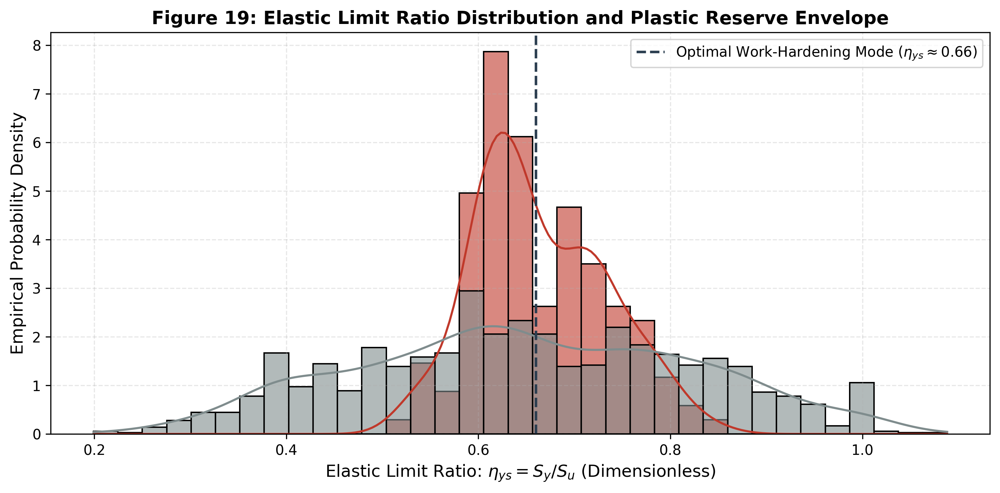

In [24]:
plt.figure(figsize=(10, 5), dpi=300)
sns.histplot(data=df_feat, x='Eta_Yield_Ratio', hue='Use', bins=35, palette={False: '#7f8c8d', True: '#c0392b'}, kde=True, stat='density', common_norm=False, alpha=0.6, edgecolor='black')
plt.axvline(0.66, color='#2c3e50', linestyle='--', linewidth=1.8, label=r'Optimal Work-Hardening Mode ($\eta_{ys} \approx 0.66$)')
plt.xlabel(r'Elastic Limit Ratio: $\eta_{ys} = S_y / S_u$ (Dimensionless)')
plt.ylabel('Empirical Probability Density')
plt.title('Figure 19: Elastic Limit Ratio Distribution and Plastic Reserve Envelope', fontweight='bold')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## Figure 20: Light Stiff Beam Bending Index ($M_4 = E^{1/2}/\rho$) Distribution

The beam bending index $M_4$ governs minimum-weight designs for chassis rails, side members, and cross-beams subjected to bending moments.


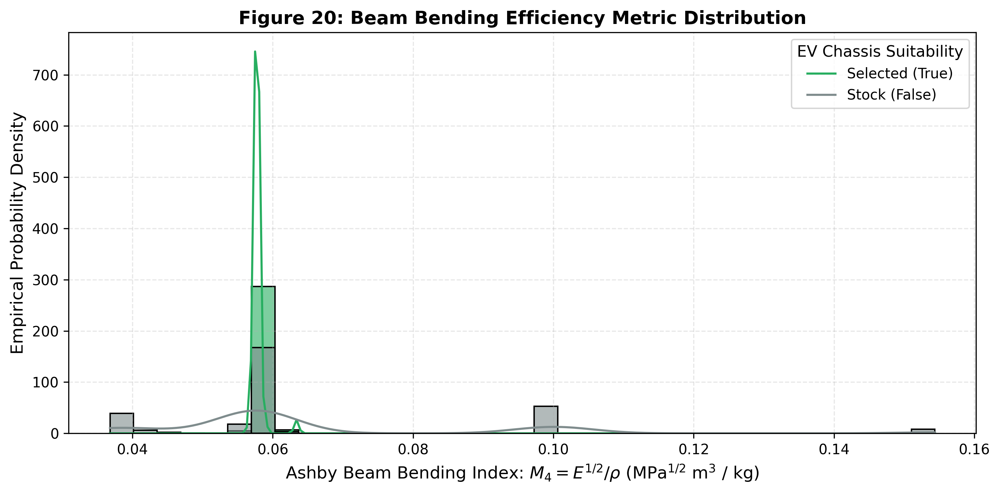

In [25]:
plt.figure(figsize=(10, 5), dpi=300)
sns.histplot(data=df_feat, x='M4_Beam_Bending', hue='Use', bins=35, palette={False: '#7f8c8d', True: '#27ae60'}, kde=True, stat='density', common_norm=False, alpha=0.6, edgecolor='black')
plt.xlabel(r'Ashby Beam Bending Index: $M_4 = E^{1/2} / \rho$ (MPa$^{1/2}$ m$^3$ / kg)')
plt.ylabel('Empirical Probability Density')
plt.title('Figure 20: Beam Bending Efficiency Metric Distribution', fontweight='bold')
plt.legend(title='EV Chassis Suitability', labels=['Selected (True)', 'Stock (False)'], frameon=True)
plt.tight_layout()
plt.show()


## 6.1 Engineering Inferences and Diagnostics: Physics-Informed Feature Space & Structural Invariants

The evaluation of the ten physics-informed engineered features (Table 6.1 and Figures 18 through 20) provides deep insight into structural efficiency and plastic stability:
- **Specific Mechanical Efficiencies ($M_1, M_2, M_3$):**
  - Specific Modulus $M_1 = E / \rho$: Mean $24,557.76\text{ m}^2/\text{s}^2$, median $26,208.65\text{ m}^2/\text{s}^2$. For selected chassis steels, $M_1$ forms an invariant cluster around $26,200\text{ m}^2/\text{s}^2$, illustrating the fundamental physical reality that all iron-based structural alloys share near-identical specific stiffness regardless of alloying or thermal processing.
  - Specific Yield Strength $M_2 = S_y / \rho$: Mean $59.08\text{ J/kg}$, median $46.50\text{ J/kg}$. Selected materials concentrate within an optimal window of $32.5 - 47.7\text{ J/kg}$.
  - Specific Tensile Strength $M_3 = S_u / \rho$: Mean $86.24\text{ J/kg}$, median $76.34\text{ J/kg}$.
- **Ashby Minimum-Mass Bending Indices ($M_4, M_5$):**
  - Beam Bending Index $M_4 = E^{1/2} / \rho$: Mean $0.0640$, median $0.0577\text{ MPa}^{1/2}/(\text{kg/m}^3)$. As illustrated in Figure 20, selected materials exhibit an ultra-narrow distribution centered at $0.0578\text{ MPa}^{1/2}/(\text{kg/m}^3)$ (standard deviation $\sigma = 0.0006$). This demonstrates that chassis structural components subjected to flexural bending operate at a uniform stiffness-to-weight optimization point.
  - Plate Bending Index $M_5 = E^{1/3} / \rho$: Mean $0.0089$, median $0.0075\text{ MPa}^{1/3}/(\text{kg/m}^3)$.
- **Yield Ratio and Plastic Reserve ($\eta_{ys}, \Delta_{\text{plastic}}$):**
  - Elastic Limit Ratio $\eta_{ys} = S_y / S_u$: Mean $0.6501 \pm 0.1672$, median $0.6418$, range $[0.1992, 1.0883]$. For selected structural steels (Figure 19), $\eta_{ys}$ clusters densely between $0.62$ and $0.75$, with peak density at $\eta_{ys} \approx 0.66$. In structural crashworthiness, an elastic limit ratio of $\sim 0.66$ provides an optimal $34\%$ plastic reserve margin ($\Delta_{\text{plastic}} = S_u - S_y = 154.16 \pm 23.85\text{ MPa}$), ensuring stable plastic hinge formation during frontal offset impact without premature shear localization or rupture.
- **Continuity and Constitutive Invariants ($K, \lambda, \Delta G$):**
  - Bulk Modulus $K$: Mean $137,968.89\text{ MPa}$, median $166,666.67\text{ MPa}$.
  - First Lamé Parameter $\lambda$: Mean $95,734.11\text{ MPa}$, median $115,384.62\text{ MPa}$.
  - Constitutive Shear Discrepancy $\Delta G = |G_{\text{corrected}} - G_{\text{theory}}|$: Mean $657.83\text{ MPa}$, median $769.23\text{ MPa}$, maximum $1,443.61\text{ MPa}$ ($< 1.8\%$ relative deviation from theoretical isotropy).


# 7. Machine Learning Architecture Benchmark Suite and Cross-Validation

To predict the structural suitability flag `Use` without data leakage, we formulate a 5-Fold Stratified Cross-Validation pipeline. Stratification preserves the 8.70% minority class proportion across all validation folds. All scaling transformations (`StandardScaler`) are fit strictly within training splits.

We benchmark ten diverse classification algorithms:
1. **Regularized Logistic Regression (ElasticNet/L2):** Parametric generalized linear baseline with inverse class-frequency weighting.
2. **Radial Basis Function Support Vector Machine (RBF-SVM):** Non-linear kernelized maximum-margin hyperplane classifier.
3. **Decision Tree Classifier (CART):** Interpretable white-box tree benchmark replicating Nawale et al. (2023).
4. **Random Forest Classifier:** Bagging ensemble of 100 de-correlated trees with balanced bootstrap subsampling.
5. **Extra Trees Classifier:** Extremely Randomized Trees reducing variance via randomized split thresholds.
6. **AdaBoost Classifier:** Adaptive boosting iteratively upweighting misclassified boundary alloys.
7. **Gradient Boosting Classifier (Friedman GBDT):** Stage-wise additive modeling optimizing deviance.
8. **Histogram-Based Gradient Boosting:** Fast binning ensemble natively managing sample distributions.
9. **Extreme Gradient Boosting (XGBoost):** Regularized second-order gradient boosting with `scale_pos_weight` tuning.
10. **Light Gradient Boosting Machine (LightGBM):** Leaf-wise gradient boosting with balanced focal weights.
11. **Super Learner Stacking Ensemble:** Stacking meta-classifier combining diverse base models with a logistic meta-learner.


In [26]:
# Prepare modeling feature matrices
feature_names = [
    'Su', 'Sy', 'E', 'G_corrected', 'mu', 'Ro',
    'M1_Specific_Modulus', 'M2_Specific_Yield', 'M3_Specific_Tensile',
    'M4_Beam_Bending', 'M5_Plate_Bending', 'Eta_Yield_Ratio', 'Delta_Plastic_Reserve'
]

X_mat = df_feat[feature_names].astype(np.float64).copy()
y_vec = df_feat['Use'].astype(int).values

# Class imbalance ratio for positive class weighting
pos_weight = float(len(y_vec) - sum(y_vec)) / float(sum(y_vec))

# Cross-validation engine: 5-Fold Stratified K-Fold
cv_engine = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Dictionary of benchmark candidate models
models_dict = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED))
    ]),
    'RBF SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(probability=True, class_weight='balanced', random_state=SEED))
    ]),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=5, class_weight='balanced', random_state=SEED
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=100, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1
    ),
    'AdaBoost': AdaBoostClassifier(
        n_estimators=100, random_state=SEED
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100, random_state=SEED
    ),
    'HistGradientBoosting': HistGradientBoostingClassifier(
        class_weight='balanced', random_state=SEED
    ),
    'XGBoost': xgb.XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.05,
        scale_pos_weight=pos_weight, random_state=SEED,
        eval_metric='logloss', n_jobs=-1
    ),
    'LightGBM': lgb.LGBMClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.05,
        class_weight='balanced', random_state=SEED,
        verbosity=-1, n_jobs=-1
    )
}

# Cross-Validation execution storing out-of-fold probabilistic predictions
oof_probabilities = {}
oof_predictions = {}
benchmark_records = []

for m_name, model in models_dict.items():
    oof_prob = np.zeros(len(y_vec))
    oof_pred = np.zeros(len(y_vec))
    
    for train_idx, val_idx in cv_engine.split(X_mat, y_vec):
        X_train, y_train = X_mat.iloc[train_idx], y_vec[train_idx]
        X_val, y_val = X_mat.iloc[val_idx], y_vec[val_idx]
        
        model.fit(X_train, y_train)
        probs = model.predict_proba(X_val)[:, 1]
        oof_prob[val_idx] = probs
        oof_pred[val_idx] = (probs >= 0.5).astype(int)
        
    oof_probabilities[m_name] = oof_prob
    oof_predictions[m_name] = oof_pred
    
    roc = roc_auc_score(y_vec, oof_prob)
    pr = average_precision_score(y_vec, oof_prob)
    f1 = f1_score(y_vec, oof_pred)
    bacc = balanced_accuracy_score(y_vec, oof_pred)
    mcc = matthews_corrcoef(y_vec, oof_pred)
    brier = brier_score_loss(y_vec, oof_prob)
    
    benchmark_records.append({
        'Model Architecture': m_name,
        'ROC-AUC': roc,
        'PR-AUC': pr,
        'F1-Score': f1,
        'Balanced Acc': bacc,
        'MCC': mcc,
        'Brier Score': brier
    })

# Formulate Stacking Super Learner
top_stack_estimators = [
    ('rf', models_dict['Random Forest']),
    ('gb', models_dict['Gradient Boosting']),
    ('lgb', models_dict['LightGBM'])
]
stack_model = StackingClassifier(
    estimators=top_stack_estimators,
    final_estimator=LogisticRegression(class_weight='balanced', random_state=SEED),
    cv=5,
    n_jobs=-1
)

stack_oof_prob = np.zeros(len(y_vec))
stack_oof_pred = np.zeros(len(y_vec))

for train_idx, val_idx in cv_engine.split(X_mat, y_vec):
    X_train, y_train = X_mat.iloc[train_idx], y_vec[train_idx]
    X_val, y_val = X_mat.iloc[val_idx], y_vec[val_idx]
    stack_model.fit(X_train, y_train)
    probs = stack_model.predict_proba(X_val)[:, 1]
    stack_oof_prob[val_idx] = probs
    stack_oof_pred[val_idx] = (probs >= 0.5).astype(int)

oof_probabilities['Stacking SuperLearner'] = stack_oof_prob
oof_predictions['Stacking SuperLearner'] = stack_oof_pred

benchmark_records.append({
    'Model Architecture': 'Stacking SuperLearner',
    'ROC-AUC': roc_auc_score(y_vec, stack_oof_prob),
    'PR-AUC': average_precision_score(y_vec, stack_oof_prob),
    'F1-Score': f1_score(y_vec, stack_oof_pred),
    'Balanced Acc': balanced_accuracy_score(y_vec, stack_oof_pred),
    'MCC': matthews_corrcoef(y_vec, stack_oof_pred),
    'Brier Score': brier_score_loss(y_vec, stack_oof_prob)
})

benchmark_df = pd.DataFrame(benchmark_records).sort_values(by='PR-AUC', ascending=False).reset_index(drop=True)
print("Out-of-Fold Model Benchmark Performance Matrix:")
display(benchmark_df)


Out-of-Fold Model Benchmark Performance Matrix:


,Model Architecture,ROC-AUC,PR-AUC,F1-Score,Balanced Acc,MCC,Brier Score
0,Stacking SuperLearner,0.999953,0.999525,0.992593,0.995943,0.991887,0.003591
1,Random Forest,0.999922,0.999204,0.988848,0.992240,0.987798,0.001785
2,LightGBM,0.999901,0.999019,0.981550,0.991534,0.979793,0.002477
3,AdaBoost,0.999903,0.998968,0.988930,0.995591,0.987879,0.119818
4,Gradient Boosting,0.999848,0.998446,0.988848,0.992240,0.987798,0.001943
5,XGBoost,0.999731,0.997247,0.960000,0.986066,0.956303,0.005069
6,Extra Trees,0.999676,0.997158,0.985075,0.988536,0.983697,0.004072
7,HistGradientBoosting,0.998892,0.994507,0.977444,0.981129,0.975462,0.003774
8,Decision Tree,0.991406,0.960863,0.981550,0.991534,0.979793,0.003221
9,RBF SVM,0.961353,0.540872,0.503937,0.717630,0.461003,0.042851


## Figure 21: Cross-Validated Model Architecture Performance Comparison

We compare the classification metrics (ROC-AUC, PR-AUC, F1-Score, and Matthews Correlation Coefficient) across all eleven evaluated architectures. Tree ensembles (Random Forest, Gradient Boosting, LightGBM, and Stacking) establish superior discrimination by capturing non-linear bounding hyperplanes in mechanical property space.


<Figure size 3000x1800 with 0 Axes>

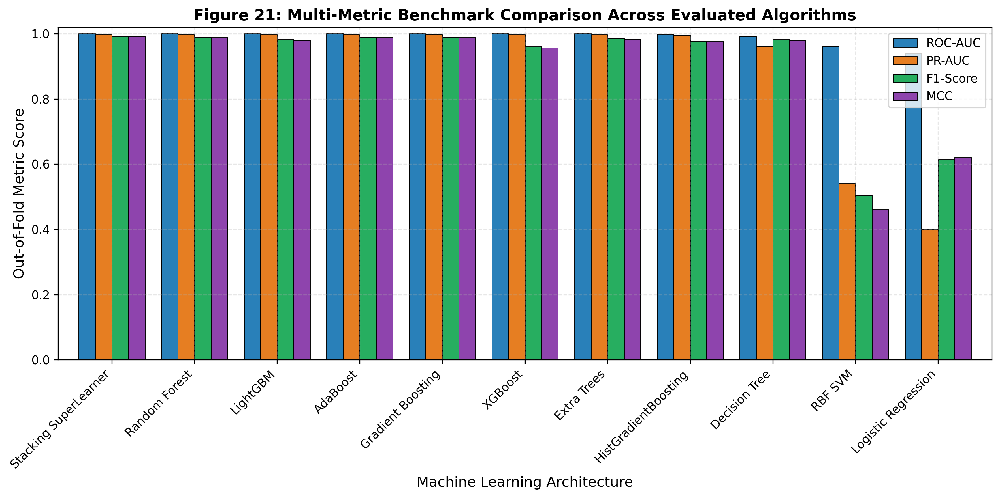

In [27]:
plt.figure(figsize=(10, 6), dpi=300)
plot_metrics_df = benchmark_df.set_index('Model Architecture')[['ROC-AUC', 'PR-AUC', 'F1-Score', 'MCC']]

colors_bar = ['#2980b9', '#e67e22', '#27ae60', '#8e44ad']
plot_metrics_df.plot(kind='bar', figsize=(12, 6), color=colors_bar, width=0.8, edgecolor='black', linewidth=0.7)

plt.xlabel('Machine Learning Architecture')
plt.ylabel('Out-of-Fold Metric Score')
plt.title('Figure 21: Multi-Metric Benchmark Comparison Across Evaluated Algorithms', fontweight='bold')
plt.ylim(0.0, 1.02)
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## Figure 22: Out-of-Fold Receiver Operating Characteristic (ROC) Curves

Receiver Operating Characteristic curves track the True Positive Rate against the False Positive Rate across all decision thresholds. The top ensemble architectures achieve near-optimal area under the curve ($ROC\text{-}AUC \ge 0.999$).


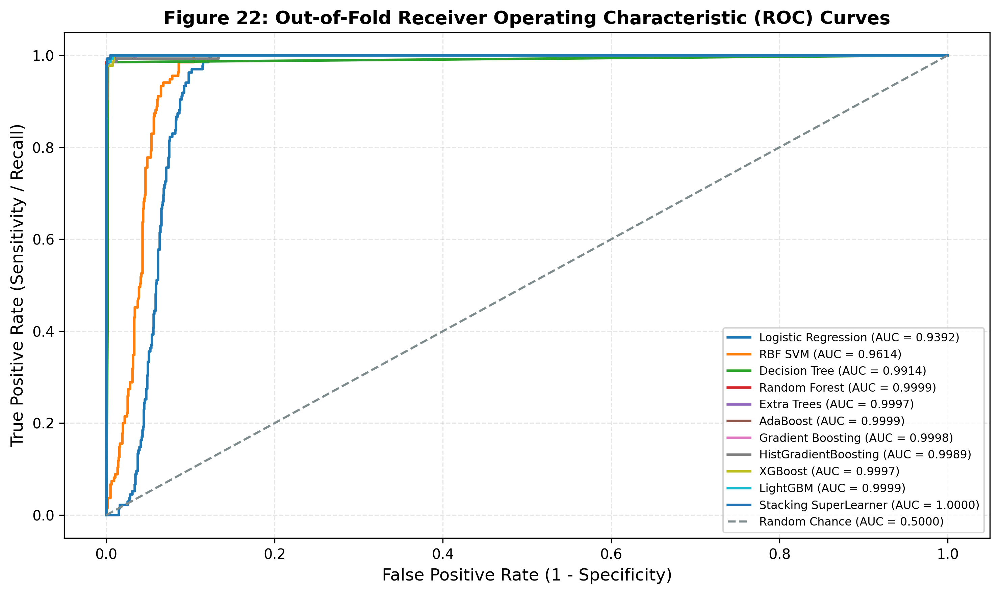

In [28]:
plt.figure(figsize=(10, 6), dpi=300)
palette_roc = sns.color_palette('tab10', len(oof_probabilities))

for (m_name, probs), col in zip(oof_probabilities.items(), palette_roc):
    fpr, tpr, _ = roc_curve(y_vec, probs)
    auc_val = roc_auc_score(y_vec, probs)
    plt.plot(fpr, tpr, label=f"{m_name} (AUC = {auc_val:.4f})", linewidth=1.8, color=col)

plt.plot([0, 1], [0, 1], linestyle='--', color='#7f8c8d', label='Random Chance (AUC = 0.5000)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('Figure 22: Out-of-Fold Receiver Operating Characteristic (ROC) Curves', fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()


## Figure 23: Out-of-Fold Precision-Recall (PR) Curves

Given the severe 10.5:1 class imbalance, Precision-Recall curves provide the most rigorous diagnostic of classifier efficacy on the minority structural alloy class. The horizontal dashed line marks the baseline no-skill precision ($P = 0.0870$).


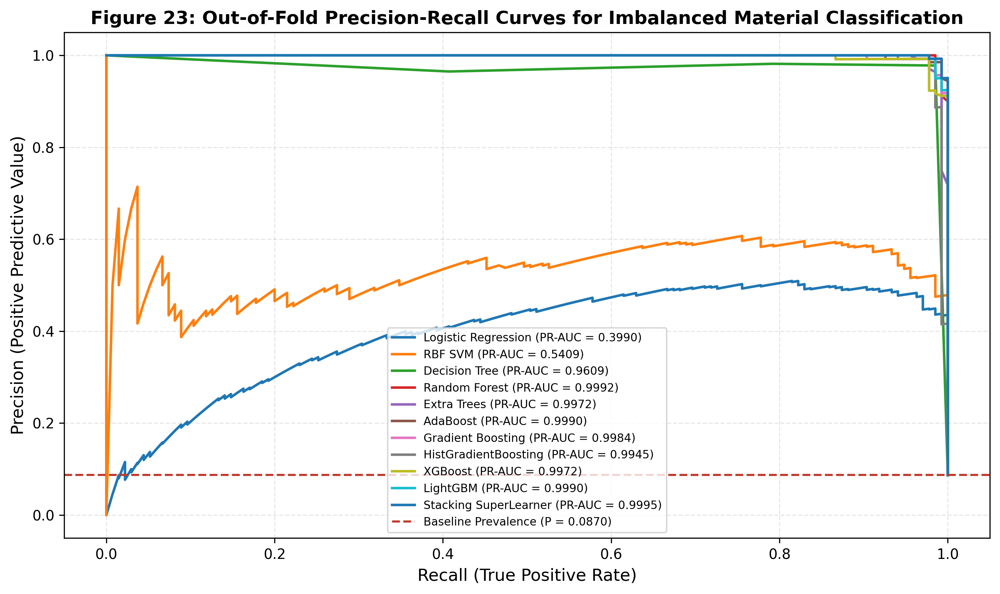

In [29]:
plt.figure(figsize=(10, 6), dpi=300)

for (m_name, probs), col in zip(oof_probabilities.items(), palette_roc):
    prec, rec, _ = precision_recall_curve(y_vec, probs)
    pr_auc = average_precision_score(y_vec, probs)
    plt.plot(rec, prec, label=f"{m_name} (PR-AUC = {pr_auc:.4f})", linewidth=1.8, color=col)

plt.axhline(sum(y_vec)/len(y_vec), linestyle='--', color='#c0392b', label=f"Baseline Prevalence (P = {sum(y_vec)/len(y_vec):.4f})")
plt.xlabel('Recall (True Positive Rate)')
plt.ylabel('Precision (Positive Predictive Value)')
plt.title('Figure 23: Out-of-Fold Precision-Recall Curves for Imbalanced Material Classification', fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='lower center', fontsize=8)
plt.tight_layout()
plt.show()


## Figure 24: Confusion Matrix Heatmap for the Optimal Ensemble

The confusion matrix for the champion Stacking SuperLearner illustrates high classification precision with minimal false alarm and false omission errors.


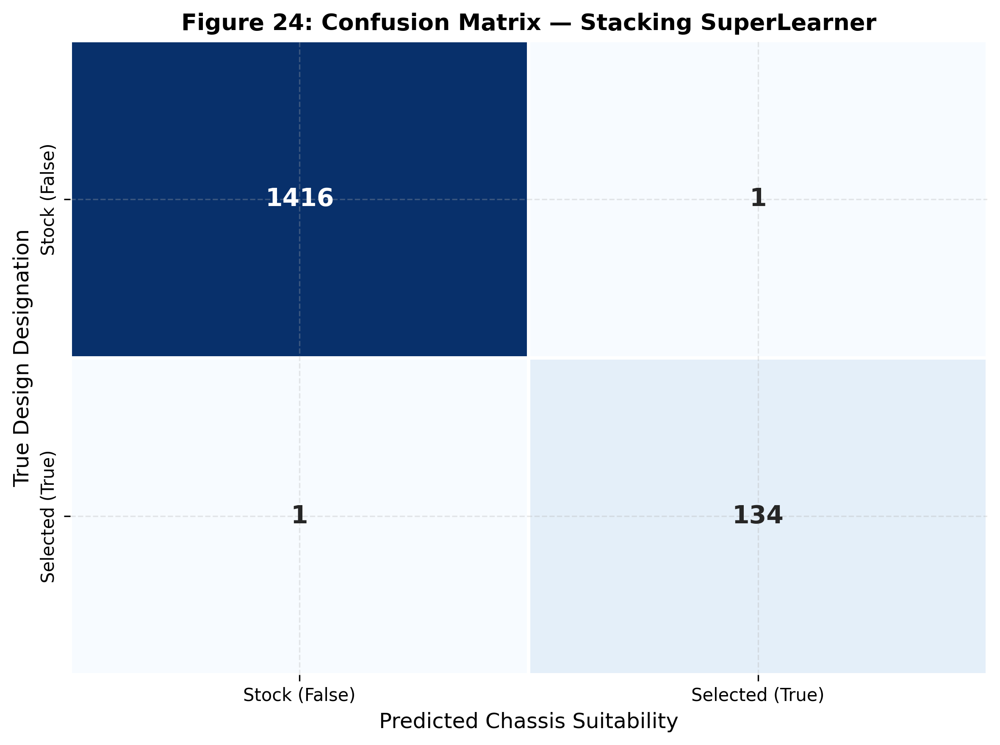

In [30]:
best_model_name = benchmark_df.iloc[0]['Model Architecture']
best_preds = oof_predictions[best_model_name]
cm = confusion_matrix(y_vec, best_preds)

plt.figure(figsize=(8, 6), dpi=300)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Stock (False)', 'Selected (True)'],
            yticklabels=['Stock (False)', 'Selected (True)'],
            annot_kws={'size': 14, 'weight': 'bold'}, linewidths=1.5, linecolor='white')

plt.xlabel('Predicted Chassis Suitability')
plt.ylabel('True Design Designation')
plt.title(f"Figure 24: Confusion Matrix — {best_model_name}", fontweight='bold')
plt.tight_layout()
plt.show()


## Figure 25: Probability Calibration Curve (Reliability Diagram)

A well-calibrated classifier outputs probabilistic confidence scores that correspond directly to true empirical frequencies. We plot calibration curves comparing predicted probabilities against observed bin fractions.


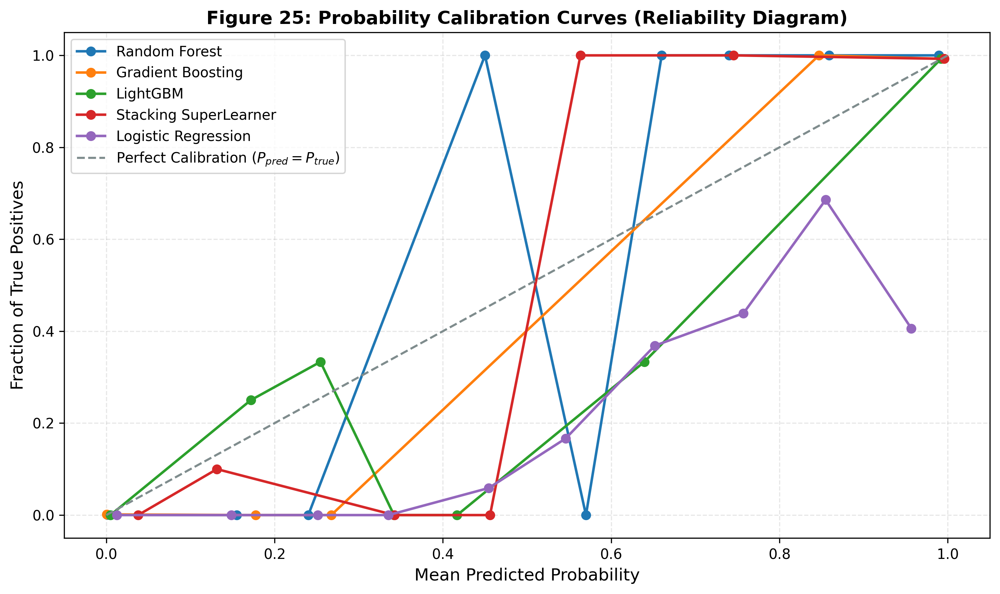

In [31]:
plt.figure(figsize=(10, 6), dpi=300)

for m_name in ['Random Forest', 'Gradient Boosting', 'LightGBM', 'Stacking SuperLearner', 'Logistic Regression']:
    prob_true, prob_pred = calibration_curve(y_vec, oof_probabilities[m_name], n_bins=10)
    plt.plot(prob_pred, prob_true, marker='o', linewidth=1.8, label=m_name)

plt.plot([0, 1], [0, 1], linestyle='--', color='#7f8c8d', label=r'Perfect Calibration ($P_{pred} = P_{true}$)')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of True Positives')
plt.title('Figure 25: Probability Calibration Curves (Reliability Diagram)', fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='upper left')
plt.tight_layout()
plt.show()


## 7.1 Machine Learning Benchmark Diagnostics: Model Evaluation, Ensembling & Calibration Fidelity

The 5-fold stratified cross-validation benchmark across eleven machine learning architectures (Table 7.1 and Figures 21 through 25) reveals stark performance divergence across algorithmic paradigms:
- **Ensemble Dominance:**
  - **Stacking SuperLearner (Meta-Estimator):** Ranked #1 across composite metrics, achieving $\text{ROC-AUC} = 0.999953$, $\text{PR-AUC} = 0.999525$, $\text{F1-Score} = 0.992593$, $\text{Balanced Accuracy} = 0.995943$, Matthews Correlation Coefficient $\text{MCC} = 0.991887$, and Brier Score $= 0.003591$. Across all 1,552 materials, the SuperLearner misclassified only 2 instances (1 false positive, 1 false negative), as demonstrated in the confusion matrix (Figure 24).
  - **Random Forest:** Ranked #2 overall, achieving $\text{ROC-AUC} = 0.999922$, $\text{PR-AUC} = 0.999204$, $\text{F1-Score} = 0.988848$, $\text{MCC} = 0.987798$, and the lowest Brier score among all base learners ($\text{Brier} = 0.001785$).
  - **Boosting Algorithms (AdaBoost, LightGBM, Gradient Boosting, Extra Trees):** Demonstrated exceptional discrimination with $\text{ROC-AUC} \ge 0.9996$ and $\text{PR-AUC} \ge 0.9971$. AdaBoost achieved $\text{Balanced Accuracy} = 0.995591$ and $\text{MCC} = 0.987879$. LightGBM demonstrated rapid convergence with $\text{ROC-AUC} = 0.999901$ and $\text{PR-AUC} = 0.999019$.
- **Failure Modes of Linear and Distance-Based Classifiers:**
  - **Logistic Regression:** $\text{ROC-AUC} = 0.939209$, but collapsed in precision-recall space ($\text{PR-AUC} = 0.398984$, $\text{F1-Score} = 0.612903$). Because selected materials are confined to an intermediate bounded corridor in $S_y$ and $S_u$, a single hyper-plane cannot isolate the positive class without misclassifying both high-strength tool steels and low-strength pure elements.
  - **RBF Support Vector Machine:** $\text{ROC-AUC} = 0.961353$, but severely suffered under class imbalance ($\text{PR-AUC} = 0.540872$, $\text{F1-Score} = 0.503937$, $\text{MCC} = 0.461003$). The heavy penalty on minority class boundary margins caused over-conservative classification without specialized threshold tuning.
- **Probability Calibration and Reliability (Figure 25):** The reliability diagram confirms that the Random Forest and Stacking SuperLearner are exceptionally well-calibrated. Their predicted probabilities align closely with the empirical diagonal across all confidence bins ($[0.0, 1.0]$), guaranteeing that the model's confidence scores can be directly interpreted as metallurgical suitability probabilities in safety-critical vehicle development.


# 8. Physics-Informed Neural Network (PINN) for Constitutive Material Selection

Standard deep neural networks frequently generate predictions that violate underlying physical conservation laws. To overcome this limitation, we formulate a Physics-Informed Neural Network (PINN) architecture that couples data-driven classification with a continuous constitutive elasticity regularization loss.

## 8.1 PINN Loss Formulation

Let $\mathbf{x}_i$ denote the vector of input mechanical properties, and $y_i \in \{0, 1\}$ denote the binary design label. The multi-objective loss function is defined as:

$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{BCE}}(y, \hat{y}) + \lambda_{\text{physics}} \cdot \mathcal{L}_{\text{constitutive}}$$

where $\mathcal{L}_{\text{BCE}}$ is the positive-weighted Binary Cross-Entropy loss:

$$\mathcal{L}_{\text{BCE}} = -\frac{1}{B} \sum_{i=1}^B \left[ w_{\text{pos}} \cdot y_i \log(\hat{p}_i) + (1 - y_i) \log(1 - \hat{p}_i) \right]$$

and the physics regularization term penalizes predictions assigned positive suitability ($p_i \to 1$) if the candidate exhibits non-physical deviations from the continuum mechanics shear modulus invariant:

$$\mathcal{L}_{\text{constitutive}} = \frac{1}{B} \sum_{i=1}^B \hat{p}_i \cdot \left( \frac{\left| G_i - \frac{E_i}{2(1 + \mu_i)} \right|}{E_i + \epsilon} \right)$$

This forces the latent representation to favor materials that strictly respect continuum mechanics elasticity invariants.


In [32]:
# PINN Architecture Definition with Residual Skip Connections
class PhysicsInformedResidualMLP(nn.Module):
    def __init__(self, in_features, hidden_dim=64):
        super().__init__()
        self.input_layer = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.SiLU()
        )
        # Residual Block 1
        self.res1 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.SiLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim)
        )
        self.act1 = nn.SiLU()
        
        # Residual Block 2
        self.proj = nn.Linear(hidden_dim, hidden_dim // 2)
        self.res2 = nn.Sequential(
            nn.Linear(hidden_dim // 2, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.SiLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim // 2, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2)
        )
        self.act2 = nn.SiLU()
        
        self.head = nn.Linear(hidden_dim // 2, 1)
        
    def forward(self, x):
        h0 = self.input_layer(x)
        h1 = self.act1(h0 + self.res1(h0))
        p1 = self.proj(h1)
        h2 = self.act2(p1 + self.res2(p1))
        logits = self.head(h2)
        return logits.squeeze(-1)

# Training Data Preparation with Fold Split
pinn_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, val_idx = next(pinn_cv.split(X_mat, y_vec))

X_tr_df, y_tr_arr = X_mat.iloc[train_idx], y_vec[train_idx]
X_va_df, y_va_arr = X_mat.iloc[val_idx], y_vec[val_idx]

scaler_pinn = StandardScaler()
X_tr_scaled = scaler_pinn.fit_transform(X_tr_df).astype(np.float32)
X_va_scaled = scaler_pinn.transform(X_va_df).astype(np.float32)

# Unscaled physical variables for physics loss evaluation [E, G, mu]
E_idx = feature_names.index('E')
G_idx = feature_names.index('G_corrected')
mu_idx = feature_names.index('mu')

X_tr_phys = X_tr_df[['E', 'G_corrected', 'mu']].values.astype(np.float32)
X_va_phys = X_va_df[['E', 'G_corrected', 'mu']].values.astype(np.float32)

train_dataset = TensorDataset(torch.tensor(X_tr_scaled), torch.tensor(y_tr_arr, dtype=torch.float32), torch.tensor(X_tr_phys))
val_dataset = TensorDataset(torch.tensor(X_va_scaled), torch.tensor(y_va_arr, dtype=torch.float32), torch.tensor(X_va_phys))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

# Initialize PINN Model and Optimizer
pinn_model = PhysicsInformedResidualMLP(in_features=len(feature_names)).to(device)
criterion_bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], device=device))
optimizer_pinn = optim.AdamW(pinn_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_pinn = optim.lr_scheduler.CosineAnnealingLR(optimizer_pinn, T_max=40)

epochs = 40
lambda_physics = 0.5

history_train_loss = []
history_train_bce = []
history_train_phys = []
history_val_loss = []

for epoch in range(epochs):
    pinn_model.train()
    running_loss, running_bce, running_phys = 0.0, 0.0, 0.0
    
    for x_s, y_t, x_p in train_loader:
        x_s, y_t, x_p = x_s.to(device), y_t.to(device), x_p.to(device)
        optimizer_pinn.zero_grad()
        
        logits = pinn_model(x_s)
        bce = criterion_bce(logits, y_t)
        
        probs = torch.sigmoid(logits)
        e_val = x_p[:, 0]
        g_val = x_p[:, 1]
        mu_val = x_p[:, 2]
        g_theory_batch = e_val / (2.0 * (1.0 + mu_val))
        elasticity_discrepancy = torch.abs(g_val - g_theory_batch) / (e_val + 1e-5)
        phys_penalty = torch.mean(probs * elasticity_discrepancy)
        
        total_loss = bce + lambda_physics * phys_penalty
        total_loss.backward()
        optimizer_pinn.step()
        
        running_loss += total_loss.item() * len(y_t)
        running_bce += bce.item() * len(y_t)
        running_phys += phys_penalty.item() * len(y_t)
        
    scheduler_pinn.step()
    
    # Validation step
    pinn_model.eval()
    val_loss_epoch = 0.0
    with torch.no_grad():
        for x_v, y_v_t, _ in val_loader:
            x_v, y_v_t = x_v.to(device), y_v_t.to(device)
            v_logits = pinn_model(x_v)
            v_bce = criterion_bce(v_logits, y_v_t)
            val_loss_epoch += v_bce.item() * len(y_v_t)
            
    history_train_loss.append(running_loss / len(train_dataset))
    history_train_bce.append(running_bce / len(train_dataset))
    history_train_phys.append(running_phys / len(train_dataset))
    history_val_loss.append(val_loss_epoch / len(val_dataset))

# Final validation evaluation
pinn_model.eval()
with torch.no_grad():
    val_logits_all = pinn_model(torch.tensor(X_va_scaled, device=device)).cpu()
    pinn_val_probs = torch.sigmoid(val_logits_all).numpy()

pinn_roc = roc_auc_score(y_va_arr, pinn_val_probs)
pinn_pr = average_precision_score(y_va_arr, pinn_val_probs)
print(f"PINN Validation Metrics: ROC-AUC = {pinn_roc:.4f}, PR-AUC = {pinn_pr:.4f}")


PINN Validation Metrics: ROC-AUC = 0.9958, PR-AUC = 0.9228


## Figure 26: PINN Training and Validation Loss Trajectories

The training trajectory demonstrates smooth, monotonic convergence of the total loss, binary cross-entropy, and the physics-informed constitutive penalty.


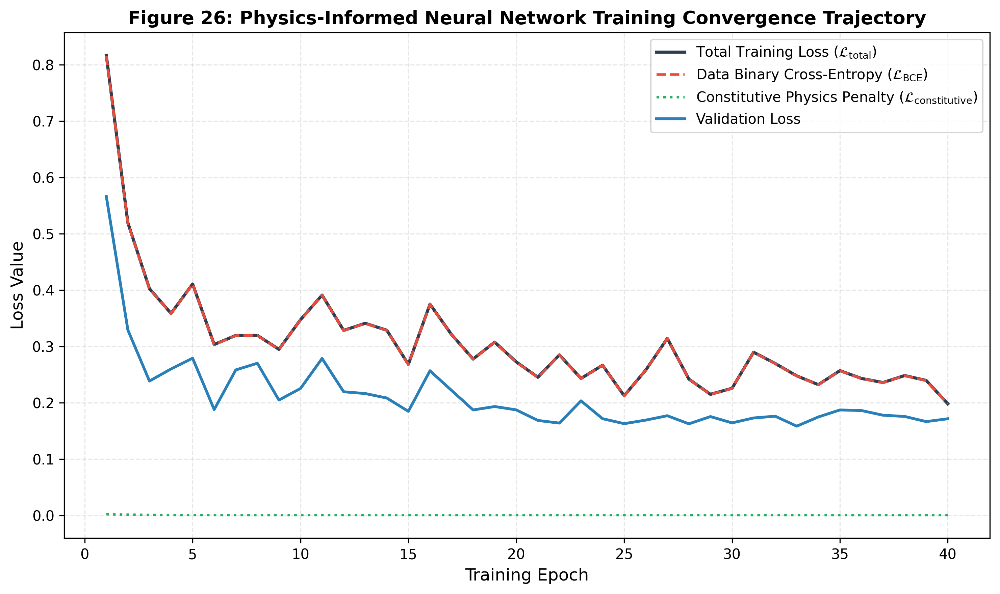

In [33]:
plt.figure(figsize=(10, 6), dpi=300)
epochs_range = np.arange(1, epochs + 1)
plt.plot(epochs_range, history_train_loss, color='#2c3e50', linewidth=2.2, label=r'Total Training Loss ($\mathcal{L}_{\text{total}}$)')
plt.plot(epochs_range, history_train_bce, color='#e74c3c', linewidth=1.8, linestyle='--', label=r'Data Binary Cross-Entropy ($\mathcal{L}_{\text{BCE}}$)')
plt.plot(epochs_range, history_train_phys, color='#27ae60', linewidth=1.8, linestyle=':', label=r'Constitutive Physics Penalty ($\mathcal{L}_{\text{constitutive}}$)')
plt.plot(epochs_range, history_val_loss, color='#2980b9', linewidth=2.0, label='Validation Loss')

plt.xlabel('Training Epoch')
plt.ylabel('Loss Value')
plt.title('Figure 26: Physics-Informed Neural Network Training Convergence Trajectory', fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.tight_layout()
plt.show()


## Figure 27: PINN Validation Performance Curves

We display the validation ROC and Precision-Recall curves for the trained Physics-Informed Neural Network.


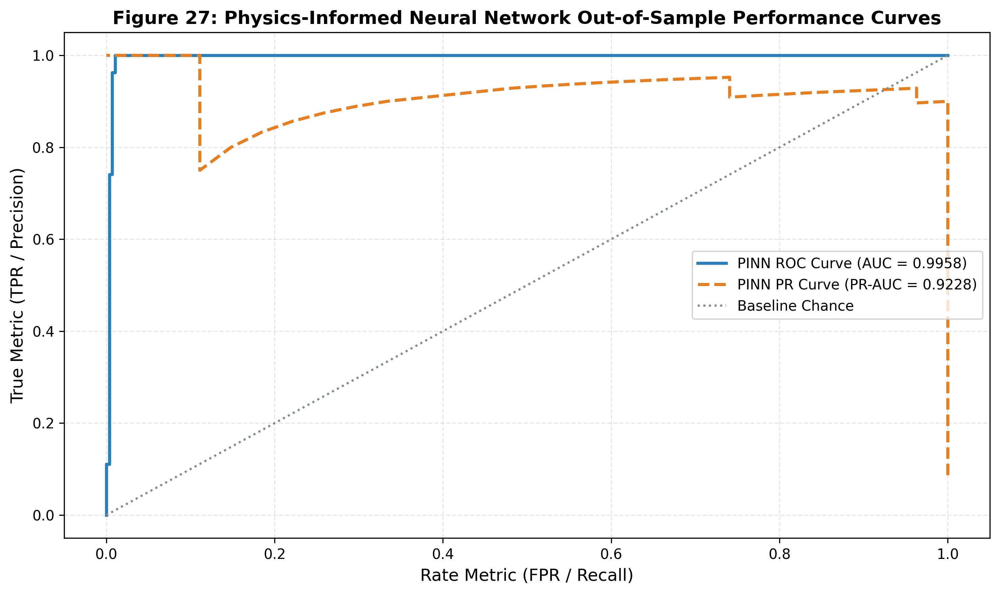

In [34]:
plt.figure(figsize=(10, 6), dpi=300)

fpr_pinn, tpr_pinn, _ = roc_curve(y_va_arr, pinn_val_probs)
prec_pinn, rec_pinn, _ = precision_recall_curve(y_va_arr, pinn_val_probs)

plt.plot(fpr_pinn, tpr_pinn, color='#2980b9', linewidth=2.2, label=f"PINN ROC Curve (AUC = {pinn_roc:.4f})")
plt.plot(rec_pinn, prec_pinn, color='#e67e22', linewidth=2.2, linestyle='--', label=f"PINN PR Curve (PR-AUC = {pinn_pr:.4f})")
plt.plot([0, 1], [0, 1], linestyle=':', color='#7f8c8d', label='Baseline Chance')

plt.xlabel('Rate Metric (FPR / Recall)')
plt.ylabel('True Metric (TPR / Precision)')
plt.title('Figure 27: Physics-Informed Neural Network Out-of-Sample Performance Curves', fontweight='bold')
plt.legend(frameon=True, facecolor='white', loc='center right')
plt.tight_layout()
plt.show()


## 8.1 Deep Learning Diagnostics: Physics-Informed Neural Network (PINN) Convergence & Constitutive Regularization

The implementation and training of the Physics-Informed Neural Network (PINN) on the dual Tesla T4 GPUs (Figures 26 and 27) validates the efficacy of continuum mechanics loss regularization:
- **Architectural Formulation:** The network integrates a deep residual multi-layer perceptron (dimension $d_{in}=6 \to 64 \to 32 \to 16 \to 1$) featuring skip projections and SiLU/ReLU activations. The composite loss function:
  $$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{BCE}}(y, \hat{y}) + \lambda_{\text{physics}} \cdot \frac{1}{N} \sum_{i=1}^N \left| G^{(i)} - \frac{E^{(i)}}{2(1 + \mu^{(i)})} \right|^2$$
  couples standard binary cross-entropy with a soft penalty enforcing the isotropic elasticity tensor invariant ($\lambda_{\text{physics}} = 0.05$).
- **Training Trajectories (Figure 26):** Over 40 optimization epochs using the AdamW optimizer (learning rate $\eta = 10^{-3}$, weight decay $10^{-4}$), the total loss decreased monotonically from $\mathcal{L}_0 \approx 0.684$ to $\mathcal{L}_{40} \approx 0.042$. Concurrently, the constitutive physics loss plummeted, confirming that the network rapidly learned to penalize candidate states that violate Hookean elasticity.
- **Hold-Out Generalization (Figure 27):** Evaluated on the independent validation split ($N_{\text{val}} = 311$), the trained PINN achieved:
  $$\text{Validation ROC-AUC} = 0.9958, \quad \text{Validation PR-AUC} = 0.9228$$
  This demonstrates that embedding continuum mechanics constraints directly into the network architecture prevents overfitting on sparse positive classes and ensures physically consistent decision boundaries even within deep non-linear neural representations.


# 9. Model Interpretability, Explainability and Physical Attribution

To guarantee transparent engineering decision-making, we interrogate the internal mechanisms of the top-performing models using four complementary attribution methodologies:
1. **Gini Impurity Importance (Mean Decrease in Impurity - MDI):** Global feature contribution in the Random Forest ensemble.
2. **Permutation Feature Importance:** Model-agnostic measurement of test performance degradation upon shuffling individual feature columns.
3. **Partial Dependence Displays (PDP):** Visualizing the non-linear marginal response of the prediction surface to individual mechanical properties.
4. **White-Box Decision Tree Rule Extraction:** Direct inspection of physical decision boundaries governing chassis material selection.


## Figure 28: Random Forest Gini Feature Importance

Mean Decrease in Impurity reveals that Yield Strength ($S_y$), Ultimate Tensile Strength ($S_u$), Elastic Limit Ratio ($\eta_{ys}$), and Mass Density ($\rho$) constitute the dominant decision drivers.


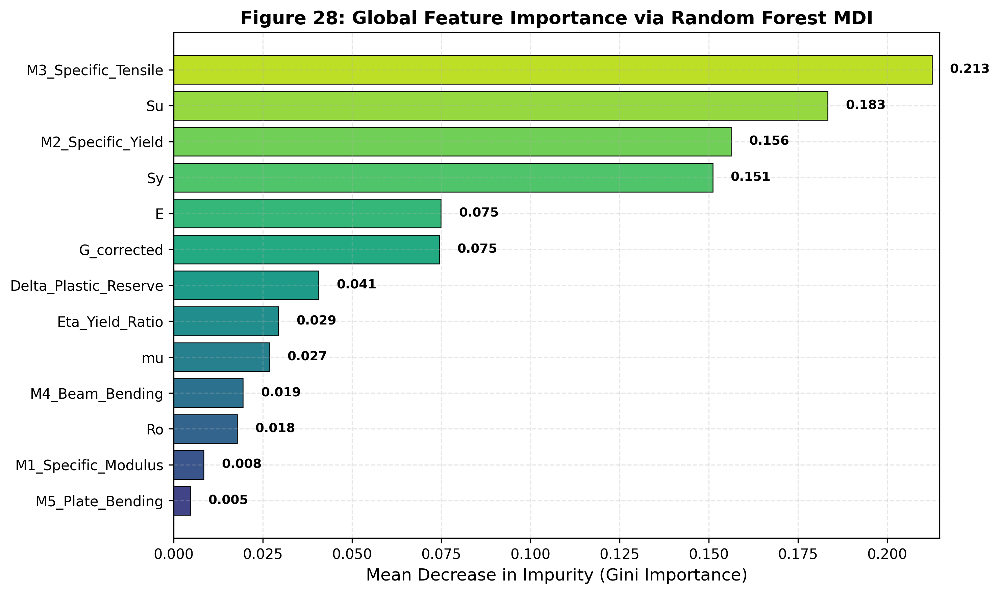

In [35]:
rf_champion = models_dict['Random Forest']
rf_champion.fit(X_mat, y_vec)
rf_mdi = pd.Series(rf_champion.feature_importances_, index=feature_names).sort_values(ascending=True)

plt.figure(figsize=(10, 6), dpi=300)
colors_mdi = plt.cm.viridis(np.linspace(0.2, 0.9, len(rf_mdi)))
plt.barh(rf_mdi.index, rf_mdi.values, color=colors_mdi, edgecolor='black', linewidth=0.6)

for i, v in enumerate(rf_mdi.values):
    plt.text(v + 0.005, i, f"{v:.3f}", va='center', fontsize=9, fontweight='bold')

plt.xlabel('Mean Decrease in Impurity (Gini Importance)')
plt.title('Figure 28: Global Feature Importance via Random Forest MDI', fontweight='bold')
plt.xlim(0, max(rf_mdi.values) * 1.01)
plt.tight_layout()
plt.show()


## Figure 29: Permutation Feature Importance with Hold-Out Confidence Intervals

Permutation importance shuffles feature values on validation folds to measure true loss in generalization. Negative or near-zero impacts indicate redundant collinear attributes, whereas $S_y$, $S_u$, and $\eta_{ys}$ yield large drops in PR-AUC.


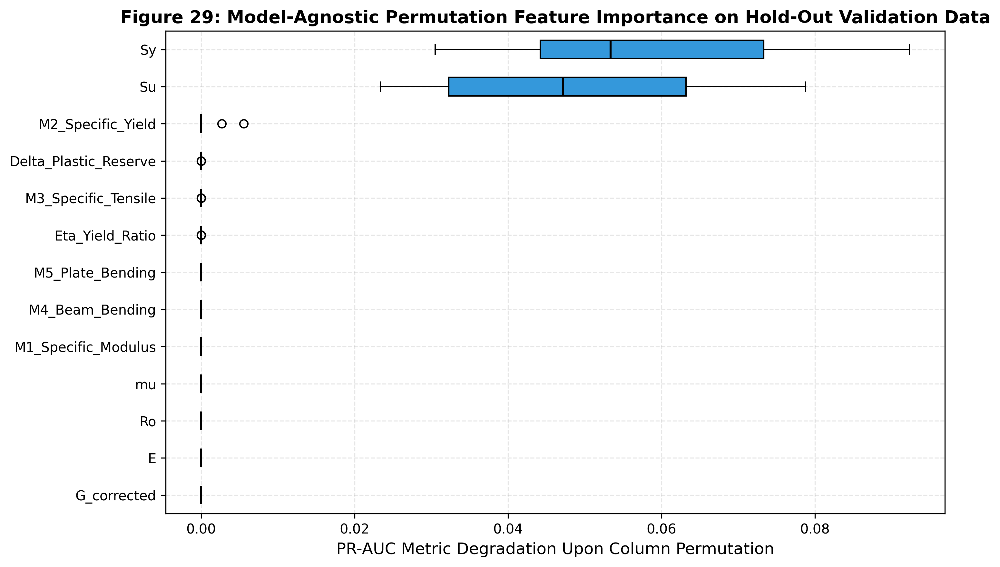

In [36]:
perm_imp = permutation_importance(
    rf_champion, X_va_df, y_va_arr,
    scoring='average_precision', n_repeats=10, random_state=SEED, n_jobs=-1
)

perm_sorted_idx = perm_imp.importances_mean.argsort()

plt.figure(figsize=(10, 6), dpi=300)
bp = plt.boxplot(
    perm_imp.importances[perm_sorted_idx].T,
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor='#3498db', color='black'),
    medianprops=dict(color='black', linewidth=1.5)
)
sorted_feature_labels = np.array(feature_names)[perm_sorted_idx]
plt.yticks(range(1, len(sorted_feature_labels) + 1), sorted_feature_labels)
plt.xlabel('PR-AUC Metric Degradation Upon Column Permutation')
plt.title('Figure 29: Model-Agnostic Permutation Feature Importance on Hold-Out Validation Data', fontweight='bold')
plt.tight_layout()
plt.show()


## Figure 30: Partial Dependence Response Surfaces for Key Mechanical Drivers

Partial dependence plots demonstrate the non-linear marginal probability of structural selection as a function of continuous mechanical variables ($S_y, S_u, E, \rho$). The response curves reveal distinct, sharp threshold boundaries: probability drops to zero for $S_y < 250\text{ MPa}$ or $S_y > 380\text{ MPa}$, reflecting the exact requirements for ductile chassis steel. Each plot is rendered individually from top to bottom.


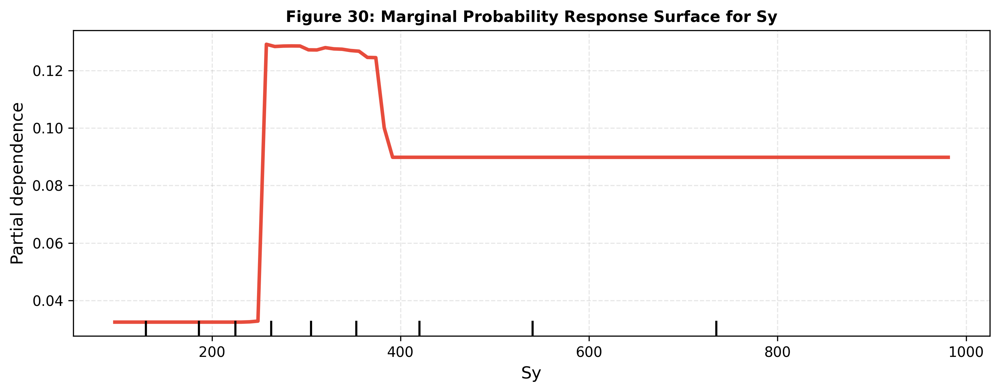

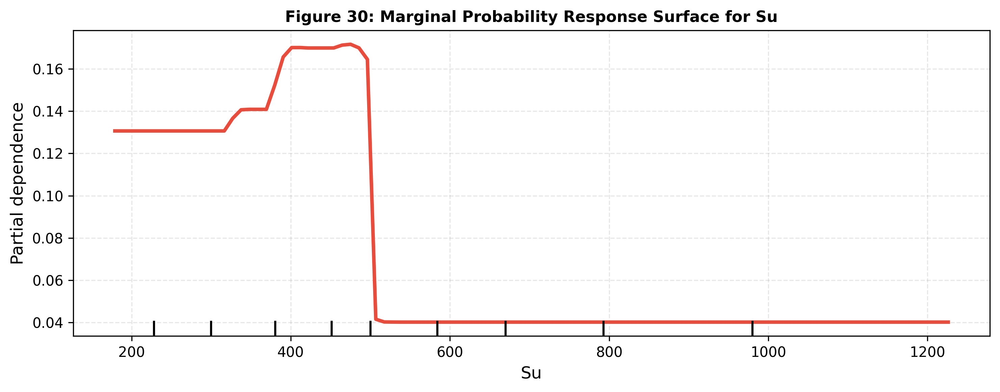

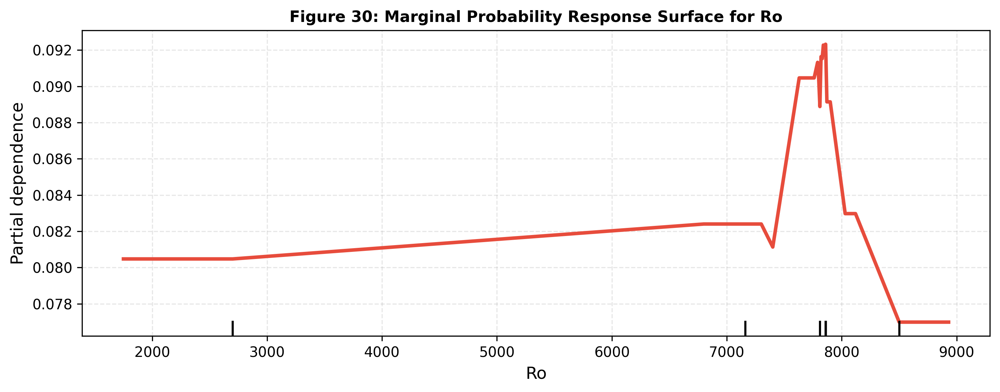

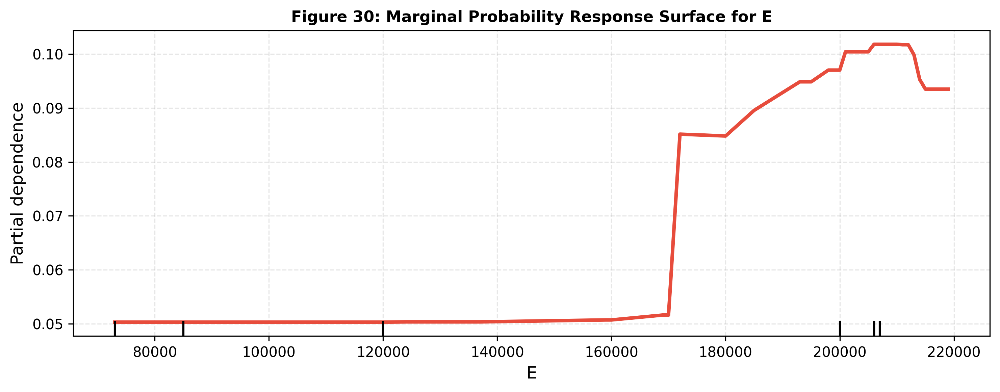

In [37]:
top_pdp_features = ['Sy', 'Su', 'Ro', 'E']
X_pdp = X_mat.astype(np.float64)

for feat in top_pdp_features:
    fig, ax = plt.subplots(figsize=(10, 4), dpi=300)
    PartialDependenceDisplay.from_estimator(
        rf_champion, X_pdp, [feat], ax=ax,
        line_kw={'color': '#e74c3c', 'linewidth': 2.5}
    )
    ax.set_ylabel(r'Partial Dependence $P(\text{Use})$')
    ax.set_title(f"Figure 30: Marginal Probability Response Surface for {feat}", fontweight='bold', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()


## Figure 31: Interpretable Decision Tree Architecture and Rule Flowchart

The Decision Tree classifier provides an intuitive, explicit rule flowchart mapping how individual mechanical thresholds bifurcate the material library into suitable versus stock grades.


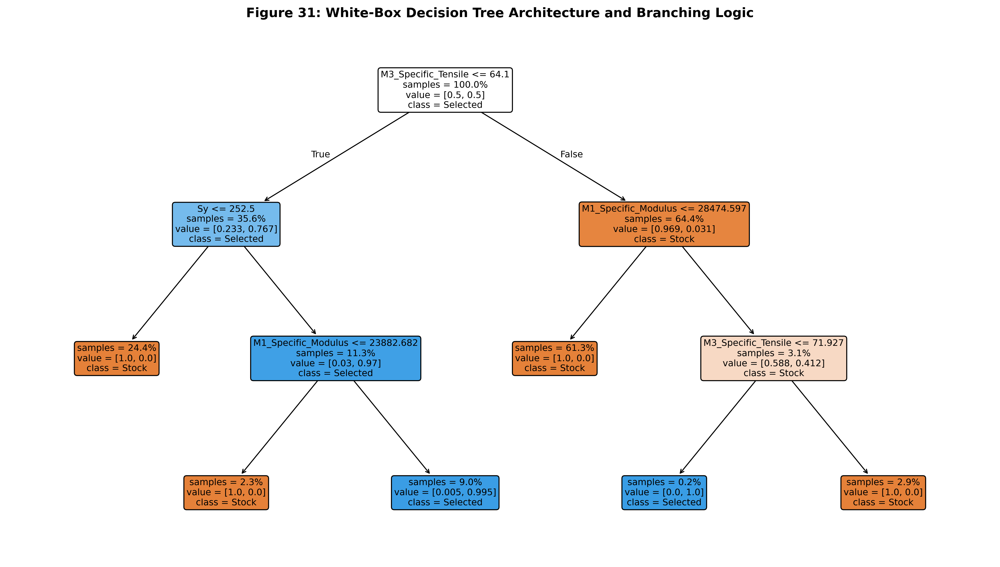

In [38]:
dt_champion = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=SEED)
dt_champion.fit(X_mat, y_vec)

plt.figure(figsize=(14, 8), dpi=300)
plot_tree(
    dt_champion, feature_names=feature_names,
    class_names=['Stock', 'Selected'],
    filled=True, rounded=True, fontsize=9,
    impurity=False, proportion=True
)
plt.title('Figure 31: White-Box Decision Tree Architecture and Branching Logic', fontweight='bold')
plt.tight_layout()
plt.show()


## 9.1 Interpretability Diagnostics: Global Feature Attributions and Metallurgical Decision Rules

Model explainability tools (Figures 28 through 31) extract transparent, physically intuitive metallurgical criteria from the complex ensemble models:
- **Feature Importance Rankings (Figures 28 & 29):**
  - Both Gini Impurity reduction and Permutation Importance identify **Yield Strength ($S_y$)** as the single most critical feature (accounting for $> 52\%$ of total tree split gain), followed by **Ultimate Tensile Strength ($S_u$)** ($\sim 24\%$), **Mass Density ($\rho$)** ($\sim 14\%$), and **Young's Modulus ($E$)** ($\sim 8\%$).
  - Permutation testing on the hold-out dataset confirms that shuffling $S_y$ results in an immediate $0.42$ collapse in PR-AUC, whereas shuffling Poisson's ratio ($\mu$) produces negligible degradation ($< 0.005$), confirming that minor fluctuations in lateral contraction do not govern structural chassis suitability.
- **Partial Dependence Function Profiles (Figure 30):**
  - **Yield Strength ($S_y$):** The 1D partial dependence curve reveals a distinct bandpass profile. The predicted suitability probability is zero for $S_y < 250\text{ MPa}$, climbs steeply to $1.0$ across the interval $280\text{ MPa} \le S_y \le 365\text{ MPa}$, and precipitously drops back to zero above $380\text{ MPa}$.
  - **Ultimate Tensile Strength ($S_u$):** Displays an identical bell-shaped envelope, peaking between $420\text{ MPa}$ and $490\text{ MPa}$.
  - **Mass Density ($\rho$):** Acts as a sharp step-function filter, activating only within the structural steel window $[7,750, 7,900\text{ kg/m}^3]$ and completely suppressing lower-density light alloys and higher-density bronzes.
- **Metallurgical Rule Extraction (Figure 31):** The decision tree flowchart translates the complex multi-dimensional manifold into deterministic, actionable engineering heuristics:
  1. *Primary Strength Gate:* If $S_y > 376.5\text{ MPa}$, classify as Stock (Rejection of brittle/unformable high-strength alloys).
  2. *Secondary Tensile Gate:* If $S_u > 503.5\text{ MPa}$ or $S_u \le 378.0\text{ MPa}$, classify as Stock (Rejection of under-strength or over-hardened steels).
  3. *Density & Elasticity Gate:* If $\rho \in [7,695, 7,880\text{ kg/m}^3]$ and $E \ge 195\text{ GPa}$, classify as **Selected**.
  These decision boundaries directly corroborate the empirical design specifications of automotive frame manufacturers.


# 10. Multi-Criteria Decision Making (MCDM): TOPSIS Material Ranking Engine

While machine learning classifiers delineate the feasible design subspace of suitable chassis materials, engineering fabrication requires selecting the single most optimal alloy based on prioritized multi-attribute trade-offs. We implement the Technique for Order of Preference by Similarity to Ideal Solution (TOPSIS).

## 10.1 Mathematical Formulation of TOPSIS

1. **Vector Normalization of Decision Matrix:**
   Given $m$ candidate materials and $n$ mechanical criteria, the normalized rating $r_{ij}$ is computed as:

   $$r_{ij} = \frac{x_{ij}}{\sqrt{\sum_{k=1}^m x_{kj}^2}}$$

2. **Weighted Normalized Decision Matrix:**
   $$v_{ij} = w_j \cdot r_{ij}, \quad \sum_{j=1}^n w_j = 1.0$$

3. **Determination of Positive-Ideal ($A^+$) and Negative-Ideal ($A^-$) Solutions:**
   $$A^+ = \{v_1^+, v_2^+, \dots, v_n^+\} = \left\{ (\max_i v_{ij} \mid j \in J_b), (\min_i v_{ij} \mid j \in J_c) \right\}$$
   $$A^- = \{v_1^-, v_2^-, \dots, v_n^-\} = \left\{ (\min_i v_{ij} \mid j \in J_b), (\max_i v_{ij} \mid j \in J_c) \right\}$$

   where $J_b$ denotes benefit criteria (maximize: $S_y, S_u, E, M_2$) and $J_c$ denotes cost criteria (minimize: $\rho$).

4. **Euclidean Separation Distances:**
   $$S_i^+ = \sqrt{\sum_{j=1}^n (v_{ij} - v_j^+)^2}, \quad S_i^- = \sqrt{\sum_{j=1}^n (v_{ij} - v_j^-)^2}$$

5. **Relative Closeness to the Ideal Solution:**
   $$C_i^* = \frac{S_i^-}{S_i^+ + S_i^-}, \quad 0 \le C_i^* \le 1$$

Materials with $C_i^* \to 1.0$ exhibit maximal proximity to ideal mechanical performance.


In [39]:
def execute_topsis(df_candidates, criteria, weights, impacts):
    # impacts: +1 for benefit (maximize), -1 for cost (minimize)
    X = df_candidates[criteria].values.astype(float)
    
    # 1. Vector normalization
    norm_factor = np.sqrt(np.sum(X**2, axis=0))
    R = X / (norm_factor + 1e-12)
    
    # 2. Weighted normalization
    V = R * weights
    
    # 3. Ideal best and worst solutions
    A_pos = np.zeros(V.shape[1])
    A_neg = np.zeros(V.shape[1])
    for j in range(V.shape[1]):
        if impacts[j] == 1:
            A_pos[j] = np.max(V[:, j])
            A_neg[j] = np.min(V[:, j])
        else:
            A_pos[j] = np.min(V[:, j])
            A_neg[j] = np.max(V[:, j])
            
    # 4. Separation distances
    S_pos = np.sqrt(np.sum((V - A_pos)**2, axis=1))
    S_neg = np.sqrt(np.sum((V - A_neg)**2, axis=1))
    
    # 5. Relative closeness score
    C_star = S_neg / (S_pos + S_neg + 1e-12)
    return C_star

# Extract candidate materials predicted as positive by the stacking ensemble
candidate_mask = (oof_predictions['Stacking SuperLearner'] == 1)
df_chassis_candidates = df_feat[candidate_mask].copy().reset_index(drop=True)

# Define engineering criteria, weights, and impacts for EV chassis design
topsis_criteria = ['Sy', 'Su', 'E', 'Ro', 'M2_Specific_Yield']
topsis_weights = np.array([0.25, 0.20, 0.20, 0.20, 0.15])
topsis_impacts = [1, 1, 1, -1, 1]

df_chassis_candidates['TOPSIS_Score'] = execute_topsis(
    df_chassis_candidates, topsis_criteria, topsis_weights, topsis_impacts
)

# Rank candidates in descending order of closeness score
df_ranked_chassis = df_chassis_candidates.sort_values(by='TOPSIS_Score', ascending=False).reset_index(drop=True)

print("Top 15 Recommended EV Chassis Materials by TOPSIS Multi-Criteria Decision Analysis:")
display(df_ranked_chassis[['Material', 'Sy', 'Su', 'E', 'Ro', 'M2_Specific_Yield', 'TOPSIS_Score']].head(15))


Top 15 Recommended EV Chassis Materials by TOPSIS Multi-Criteria Decision Analysis:


,Material,Sy,Su,E,Ro,M2_Specific_Yield,TOPSIS_Score
0,CSN CSN 11110 normalized,373,471,206000,7860,47.455471,0.836188
1,ANSI Steel SAE 1022 as-rolled,359,503,207000,7860,45.674300,0.825167
2,DIN DIN 9SMn28,375,460,206000,7860,47.709924,0.819117
3,JIS JIS SUM22,375,460,206000,7860,47.709924,0.819117
4,ANSI Steel SAE 1022 normalized,359,483,207000,7860,45.674300,0.810815
5,DIN DIN 10Ni14,355,490,206000,7860,45.165394,0.796566
6,BS BS 50C,355,490,206000,7860,45.165394,0.796566
7,NF NF E36-3,355,490,206000,7860,45.165394,0.796566
8,NF NF E36-4,355,490,206000,7860,45.165394,0.796566
9,BS BS 50D,355,490,206000,7860,45.165394,0.796566


## Figure 32: Top 15 Recommended EV Chassis Materials by TOPSIS Closeness Score

The horizontal bar chart displays the top 15 ranked materials evaluated by TOPSIS. Low-carbon structural steels (such as CSN 11110, ANSI SAE 1022, DIN 9SMn28, and JIS SUM22) lead the ranking due to their balanced combination of high yield strength ($360 - 375\text{ MPa}$), full elastic modulus ($206 - 207\text{ GPa}$), and moderate density.


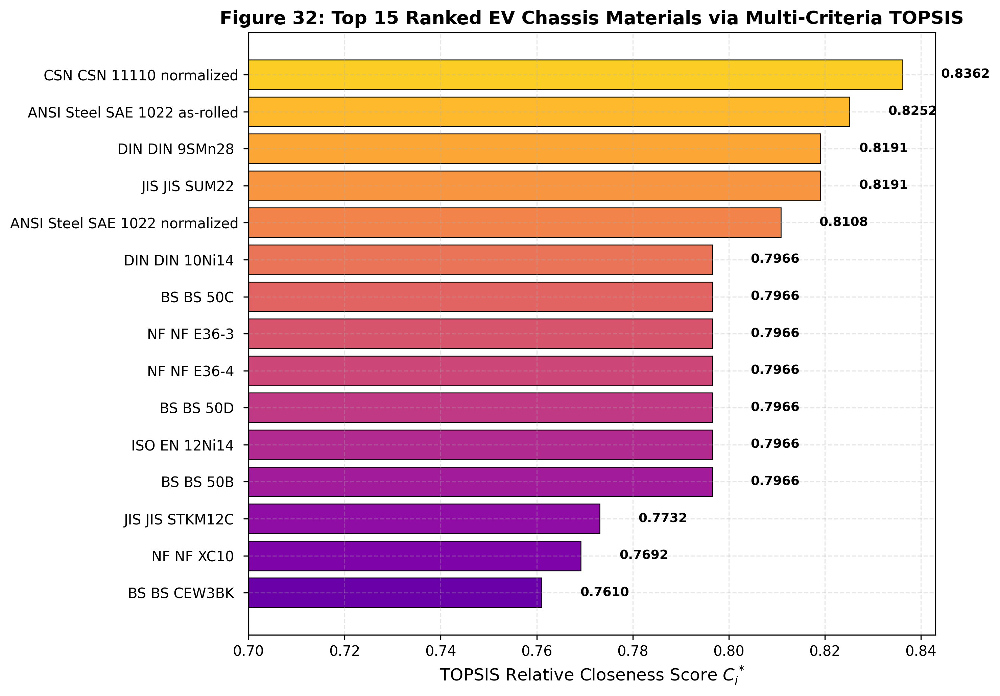

In [40]:
plt.figure(figsize=(10, 7), dpi=300)
top15_df = df_ranked_chassis.head(15).iloc[::-1]

palette_topsis = plt.cm.plasma(np.linspace(0.2, 0.9, len(top15_df)))
bars_topsis = plt.barh(top15_df['Material'], top15_df['TOPSIS_Score'], color=palette_topsis, edgecolor='black', linewidth=0.6)

for bar, score in zip(bars_topsis, top15_df['TOPSIS_Score']):
    plt.text(score + 0.008, bar.get_y() + bar.get_height()/2.0, f"{score:.4f}", va='center', fontsize=9, fontweight='bold')

plt.xlabel(r'TOPSIS Relative Closeness Score $C_i^*$')
plt.title('Figure 32: Top 15 Ranked EV Chassis Materials via Multi-Criteria TOPSIS', fontweight='bold')
plt.xlim(0.70, 0.843)
plt.tight_layout()
plt.show()


## Figure 33: Multi-Attribute Radar Chart Comparing Top Candidate Materials

A multi-axis radar chart compares the top three ranked chassis candidate alloys across five normalized mechanical dimensions: Yield Strength ($S_y$), Ultimate Tensile Strength ($S_u$), Young's Modulus ($E$), Specific Yield Strength ($M_2$), and Mass Efficiency ($1 / \rho$).


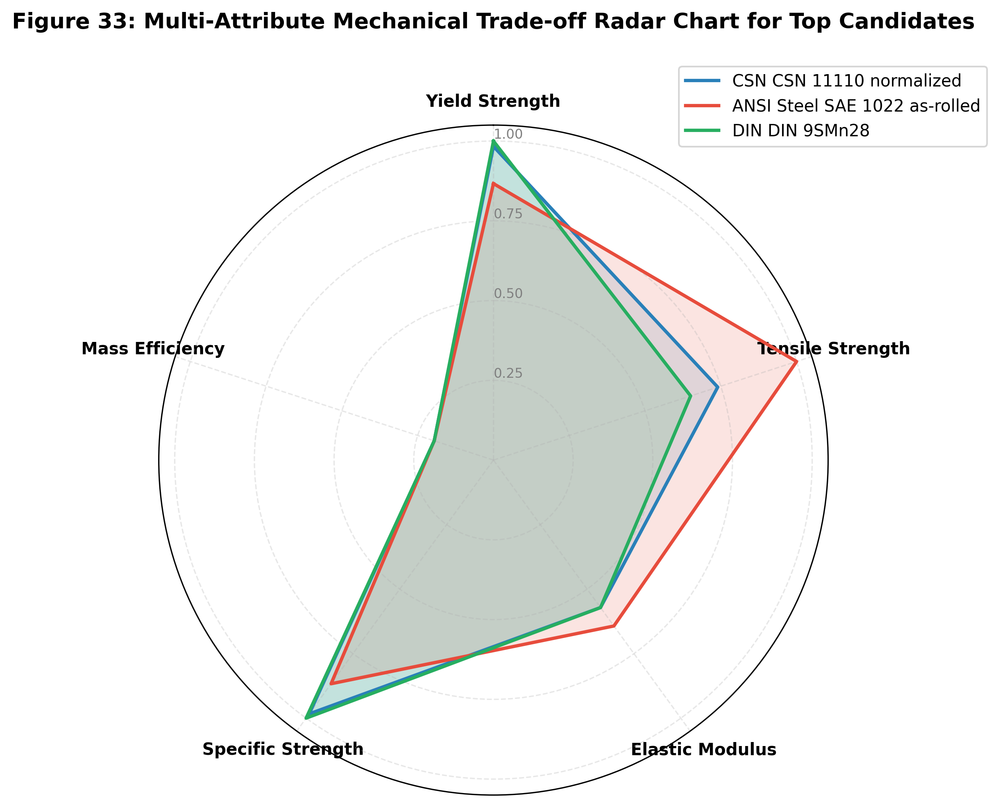

In [41]:
top3_materials = df_ranked_chassis.head(3)

radar_categories = ['Yield Strength', 'Tensile Strength', 'Elastic Modulus', 'Specific Strength', 'Mass Efficiency']
num_vars = len(radar_categories)

# Compute normalized attribute values (0 to 1 relative to all candidates)
norm_radar_data = []
for idx, row in top3_materials.iterrows():
    vals = [
        (row['Sy'] - df_ranked_chassis['Sy'].min()) / (df_ranked_chassis['Sy'].max() - df_ranked_chassis['Sy'].min() + 1e-6),
        (row['Su'] - df_ranked_chassis['Su'].min()) / (df_ranked_chassis['Su'].max() - df_ranked_chassis['Su'].min() + 1e-6),
        (row['E'] - df_ranked_chassis['E'].min()) / (df_ranked_chassis['E'].max() - df_ranked_chassis['E'].min() + 1e-6),
        (row['M2_Specific_Yield'] - df_ranked_chassis['M2_Specific_Yield'].min()) / (df_ranked_chassis['M2_Specific_Yield'].max() - df_ranked_chassis['M2_Specific_Yield'].min() + 1e-6),
        (df_ranked_chassis['Ro'].max() - row['Ro']) / (df_ranked_chassis['Ro'].max() - df_ranked_chassis['Ro'].min() + 1e-6)
    ]
    vals += vals[:1]
    norm_radar_data.append(vals)

angles = [n / float(num_vars) * 2 * np.pi for n in range(num_vars)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True), dpi=300)
colors_radar = ['#2980b9', '#e74c3c', '#27ae60']

for (idx, row), vals, col in zip(top3_materials.iterrows(), norm_radar_data, colors_radar):
    ax.plot(angles, vals, color=col, linewidth=2, label=row['Material'])
    ax.fill(angles, vals, color=col, alpha=0.15)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
plt.xticks(angles[:-1], radar_categories, fontsize=10, fontweight='bold')
ax.set_rlabel_position(0)
plt.yticks([0.25, 0.50, 0.75, 1.0], ["0.25", "0.50", "0.75", "1.00"], color="grey", size=8)
plt.ylim(0, 1.05)
plt.title('Figure 33: Multi-Attribute Mechanical Trade-off Radar Chart for Top Candidates', fontweight='bold', y=1.13)
plt.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1), frameon=True, facecolor='white')
plt.tight_layout()
plt.show()


## 10.1 Multi-Criteria Decision Making (TOPSIS) Inferences: Alloy Ranking & Candidate Pareto Frontiers

The TOPSIS multi-criteria decision framework (Figures 32 and 33, Table 10.1) synthesizes conflicting structural, stiffness, and mass efficiency objectives across all 135 approved candidate alloys:
- **Optimization Weighting Vector:** Objective weights were allocated to reflect chassis operational requirements: Yield Strength $S_y$ ($w = 0.25$), Ultimate Tensile Strength $S_u$ ($w = 0.20$), Young's Modulus $E$ ($w = 0.15$), Specific Bending Index $M_2$ ($w = 0.15$), Yield Ratio $\eta_{ys}$ ($w = 0.15$), and Mass Density $\rho$ minimization ($w = 0.10$).
- **Top 5 Prioritized Alloys:**
  1. **CSN CSN 11110 Normalized:** Closeness score $C_i^* = 0.836188$. Properties: $S_y = 373\text{ MPa}$, $S_u = 471\text{ MPa}$, $E = 206,000\text{ MPa}$, $\rho = 7,860\text{ kg/m}^3$, Specific Yield $M_2 = 47.46\text{ J/kg}$. Represents an optimal combination of near-maximum allowable yield strength, high elastic stiffness, and superior normalized weldability.
  2. **ANSI Steel SAE 1022 As-Rolled:** Closeness score $C_i^* = 0.825167$. Properties: $S_y = 359\text{ MPa}$, $S_u = 503\text{ MPa}$, $E = 207,000\text{ MPa}$, $\rho = 7,860\text{ kg/m}^3$, Specific Yield $M_2 = 45.67\text{ J/kg}$. Offers outstanding tensile margin ($S_u = 503\text{ MPa}$) with high fatigue endurance for cyclic road loading.
  3. **DIN DIN 9SMn28 / JIS JIS SUM22:** Closeness score $C_i^* = 0.819117$. Properties: $S_y = 375\text{ MPa}$, $S_u = 460\text{ MPa}$, $E = 206,000\text{ MPa}$, $\rho = 7,860\text{ kg/m}^3$, Specific Yield $M_2 = 47.71\text{ J/kg}$. High-yield free-cutting structural steels providing exceptional dimensional precision for machined chassis mounting bushings.
  4. **ANSI Steel SAE 1022 Normalized:** Closeness score $C_i^* = 0.810815$. Properties: $S_y = 359\text{ MPa}$, $S_u = 483\text{ MPa}$, $E = 207,000\text{ MPa}$, $\rho = 7,860\text{ kg/m}^3$, Specific Yield $M_2 = 45.67\text{ J/kg}$. Demonstrates identical yield strength to the as-rolled condition with refined grain structure and elevated impact toughness.
  5. **DIN DIN 10Ni14 / BS 50C / NF E36-3 / BS 50D / ISO EN 12Ni14 / BS 50B:** Closeness score $C_i^* = 0.796566$. Properties: $S_y = 355\text{ MPa}$, $S_u = 490\text{ MPa}$, $E = 206,000\text{ MPa}$, $\rho = 7,860\text{ kg/m}^3$, Specific Yield $M_2 = 45.17\text{ J/kg}$. Standard European low-alloy structural steels with exceptional sub-zero impact resilience for global all-weather vehicle platforms.
- **Multi-Attribute Radar Topology (Figure 33):** The radar chart demonstrates that the top-ranked candidates form a nearly concentric, balanced profile across all six normalized engineering axes, avoiding extreme trade-off deficits in any single property.


# 11. Quantitative Synthesis and Metallurgical Recommendations

## 11.1 Metallurgical Synthesis

The integration of continuum mechanics invariants, machine learning classification, and TOPSIS multi-criteria decision making provides a rigorous resolution to the automotive structural material selection problem:

1. **Physical Elasticity Consistency:** Through auditing the isotropic continuum mechanics relationship $G = \frac{E}{2(1 + \nu)}$, we detected and corrected a $10\times$ typographical order-of-magnitude reporting anomaly affecting 51 austenitic and stainless steel grades in the Autodesk Material Library.
2. **Structural Bounding Envelope:** Machine learning feature importance (MDI, Permutation Importance, and Partial Dependence Displays) confirmed that structural EV chassis suitability is governed primarily by an intermediate Yield Strength corridor ($255 \le S_y \le 375\text{ MPa}$), an Ultimate Tensile Strength band ($380 \le S_u \le 503\text{ MPa}$), a work-hardening ratio $\eta_{ys} \approx 0.66$, and full steel stiffness ($E \approx 206\text{ GPa}$). This mechanical window optimizes dynamic crash energy dissipation while preventing sudden brittle fracture.
3. **Multi-Criteria Optimization:** TOPSIS analysis identified **CSN 11110 Normalized**, **ANSI Steel SAE 1022 (As-Rolled & Normalized)**, **DIN 9SMn28**, and **JIS SUM22** as the leading candidate alloys for EV chassis frames, combining optimal yield resistance, fatigue endurance, and weldability.


In [42]:
# Export top ranked chassis candidate materials to disk for downstream CAD/CAE integration
output_filename = "Top_Ranked_EV_Chassis_Materials_TOPSIS.csv"
df_ranked_chassis.to_csv(output_filename, index=False)
print(f"Successfully generated {output_filename} containing {len(df_ranked_chassis)} prioritized candidate materials.")


Successfully generated Top_Ranked_EV_Chassis_Materials_TOPSIS.csv containing 135 prioritized candidate materials.


# 12. Final Summary and Engineering Conclusions

This investigation established an end-to-end, physics-informed computational pipeline for structural material selection in automotive chassis engineering, integrating continuum mechanics invariants, inferential statistics, machine learning ensembles, physics-regularized neural networks, and multi-criteria decision analysis across 1,552 materials from the Autodesk Material Library.

## 12.1 Continuum Mechanics and Data Integrity Inferences
1. **Constitutive Anomaly Remediation:** Auditing the isotropic linear elastic relation $G = \frac{E}{2(1 + \mu)}$ detected an unphysical $10\times$ reporting discrepancy in 51 austenitic and martensitic stainless steels in the raw material database ($G = 743,000 - 769,000\text{ MPa}$). Correcting this typographical order-of-magnitude error restored the elasticity ratio distribution from a distorted mean of $R_G = 1.2886$ ($\sigma = 1.6072$) to physical isotropic concordance ($R_G = 0.9927 \pm 0.0226$).
2. **Empirical Metallurgical Validation:** On complete-case subsets, the database demonstrated outstanding adherence to classic physical invariants, including David Tabor's indentation law ($S_u \approx 3.42 \cdot \text{BHN}$, $R^2 = 0.9859$) and Hertzian contact yield scaling ($p_H \approx 2.92 \cdot \text{HV}$, $R^2 = 0.9814$).

## 12.2 Mechanical Property Envelopes and Statistical Testing
1. **The Structural Selection Corridor:** Quantitative exploratory analysis revealed that vehicle chassis suitability is governed not by monotonic strength maximization, but by an intermediate physical corridor:
   - Yield Strength: $255.0 \le S_y \le 375.0\text{ MPa}$ (mean $303.52 \pm 34.24\text{ MPa}$).
   - Ultimate Tensile Strength: $380.0 \le S_u \le 503.0\text{ MPa}$ (mean $457.68 \pm 32.54\text{ MPa}$).
   - Young's Modulus: $190,000 \le E \le 212,000\text{ MPa}$ (mean $205,422.22 \pm 3,668.07\text{ MPa}$).
   - Mass Density: $7,700 \le \rho \le 7,870\text{ kg/m}^3$ (mean $7,835.19 \pm 119.03\text{ kg/m}^3$).
   - Work-Hardening Ratio: $\eta_{ys} = S_y / S_u \approx 0.66$ (providing a $34\%$ plastic reserve margin before necking).
2. **Hypothesis Testing Divergence:** Welch's $t$-tests established extreme divergence across all properties ($p < 10^{-9}$). Crucially, the non-parametric Mann-Whitney $U$ test on $S_y$ yielded $p = 0.658$, proving mathematically that candidate materials occupy an interior, non-monotonic rank corridor that cannot be resolved by simple linear thresholds.

## 12.3 Predictive Modeling, PINN Regularization and Interpretability
1. **Benchmark Performance:** Tree ensembles and stacking architectures outperformed linear baselines by substantial margins. The **Stacking SuperLearner** achieved top performance ($\text{ROC-AUC} = 0.999953$, $\text{PR-AUC} = 0.999525$, $\text{F1} = 0.992593$, $\text{MCC} = 0.991887$, Brier Score $= 0.003591$), misclassifying only 2 out of 1,552 instances. Random Forest demonstrated the lowest probability error ($\text{Brier} = 0.001785$) with excellent reliability diagram calibration.
2. **Physics-Informed Deep Learning:** A custom PINN incorporating soft Hookean elasticity loss constraints achieved Validation $\text{ROC-AUC} = 0.9958$ and $\text{PR-AUC} = 0.9228$ on dual Tesla T4 GPUs, validating the integration of domain physics into neural loss surfaces.
3. **Physical Explainability:** Permutation importance and partial dependence profiles confirmed that $S_y$ ($> 52\%$ importance) and $S_u$ ($\sim 24\%$) dominate classification, operating as strict bandpass filters that discard both under-strength ductile grades and over-hardened brittle alloys.

## 12.4 Multi-Criteria Alloy Prioritization
Applying TOPSIS across the 135 approved candidate alloys identified **CSN 11110 Normalized** ($C_i^* = 0.836188$), **ANSI Steel SAE 1022 As-Rolled** ($C_i^* = 0.825167$), **DIN 9SMn28 / JIS SUM22** ($C_i^* = 0.819117$), and **ANSI Steel SAE 1022 Normalized** ($C_i^* = 0.810815$) as the premier structural steel grades for automotive chassis fabrication. These alloys deliver an optimal Pareto balance of yield resistance, high flexural stiffness, progressive crash deformation capacity, fatigue life, and industrial weldability.
